In [1]:
import os
import pandas as pd
import numpy as np

# Dataset paths
DATA_DIR = "/kaggle/input/datasets/mshamoonbutt/hospital-management-system"

EXCEL_PATH = os.path.join(DATA_DIR, "Hospital Management System.xlsx")
SQL_PATH = os.path.join(DATA_DIR, "Hospital_Management_System.sql")
ERD_PATH = os.path.join(DATA_DIR, "G2_Hospital_Management_Sytem_ERD_final.jpg")
README_PATH = os.path.join(DATA_DIR, "readme.md")

# Verify that the expected files exist
for name, path in {
    "Excel workbook": EXCEL_PATH,
    "SQL script": SQL_PATH,
    "ERD diagram": ERD_PATH,
    "README": README_PATH
}.items():
    print(f"{name}: {'Found' if os.path.exists(path) else 'Not found'}")

Excel workbook: Found
SQL script: Found
ERD diagram: Found
README: Found


In [2]:
excel_file = pd.ExcelFile(EXCEL_PATH)
sheet_names = excel_file.sheet_names

print(f"Number of tables: {len(sheet_names)}")
print("\nTable names:")

for sheet in sheet_names:
    print(f"- {sheet}")

Number of tables: 14

Table names:
- Appointment
- Bed
- BedRecords
- Department
- Doctor
- Helpers
- MedicalRecord
- Nurse
- Patients
- Room
- RoomRecords
- StaffShift
- SurgeryRecord
- Ward


In [3]:
table_profiles = []

for sheet in sheet_names:
    df = pd.read_excel(EXCEL_PATH, sheet_name=sheet)

    table_profiles.append({
        "Table": sheet,
        "Rows": len(df),
        "Columns": len(df.columns),
        "Column Names": ", ".join(df.columns.astype(str)),
        "Data Types": ", ".join(
            f"{col}: {dtype}"
            for col, dtype in df.dtypes.items()
        )
    })

table_profiles_df = pd.DataFrame(table_profiles)

display(table_profiles_df)

,Table,Rows,Columns,Column Names,Data Types
0,Appointment,1000,9,"appoIntment_Id, patient_Id, doct_Id, reason, a...","appoIntment_Id: int64, patient_Id: int64, doct..."
1,Bed,500,2,"bed_No, ward_No","bed_No: int64, ward_No: int64"
2,BedRecords,1000,9,"admission_Id, bed_No, patient_Id, nurse_Id, he...","admission_Id: int64, bed_No: int64, patient_Id..."
3,Department,31,2,"dept_Id, dept_Name","dept_Id: int64, dept_Name: object"
4,Doctor,400,8,"doct_Id, dept_Id, FName, LName, Gender, contac...","doct_Id: int64, dept_Id: int64, FName: object,..."
5,Helpers,1100,6,"helper_Id, dept_Id, FName, LName, Gender, cont...","helper_Id: int64, dept_Id: int64, FName: objec..."
6,MedicalRecord,3000,11,"record_Id, doct_Id, patient_Id, visit_Date, cu...","record_Id: int64, doct_Id: int64, patient_Id: ..."
7,Nurse,500,6,"nurse_Id, dept_Id, FName, LName, Gender, conat...","nurse_Id: int64, dept_Id: int64, FName: object..."
8,Patients,1500,7,"patient_Id, FName, LName, Gender, Date_Of_Birt...","patient_Id: int64, FName: object, LName: objec..."
9,Room,391,3,"room_No, dept_Id, room_Type","room_No: int64, dept_Id: int64, room_Type: object"


In [4]:
quality_results = []

for sheet in sheet_names:
    df = pd.read_excel(EXCEL_PATH, sheet_name=sheet)

    quality_results.append({
        "Table": sheet,
        "Rows": len(df),
        "Missing Cells": int(df.isna().sum().sum()),
        "Columns With Missing Values": int(df.isna().any().sum()),
        "Duplicate Rows": int(df.duplicated().sum())
    })

quality_df = pd.DataFrame(quality_results)

display(quality_df)

,Table,Rows,Missing Cells,Columns With Missing Values,Duplicate Rows
0,Appointment,1000,0,0,0
1,Bed,500,0,0,0
2,BedRecords,1000,0,0,0
3,Department,31,0,0,0
4,Doctor,400,400,2,0
5,Helpers,1100,0,0,0
6,MedicalRecord,3000,1531,1,0
7,Nurse,500,0,0,0
8,Patients,1500,0,0,0
9,Room,391,0,0,0


In [5]:
for sheet in sheet_names:
    df = pd.read_excel(EXCEL_PATH, sheet_name=sheet)

    missing = df.isna().sum()
    missing = missing[missing > 0]

    if len(missing) > 0:
        print(f"\n--- {sheet} ---")

        for column, count in missing.items():
            percentage = count / len(df) * 100
            print(
                f"{column}: {count} missing "
                f"({percentage:.1f}%)"
            )


--- Doctor ---
surgeon_Type: 362 missing (90.5%)
office_No: 38 missing (9.5%)

--- MedicalRecord ---
next_Visit: 1531 missing (51.0%)

--- StaffShift ---
doct_Id: 1000 missing (48.6%)
nurse_Id: 1558 missing (75.7%)
helper_Id: 1558 missing (75.7%)


In [6]:
staff_shift = pd.read_excel(
    EXCEL_PATH,
    sheet_name="StaffShift"
)

staff_columns = ["doct_Id", "nurse_Id", "helper_Id"]

display(staff_shift[staff_columns].head(10))

print("\nNumber of populated assignments per row:")
display(staff_shift[staff_columns].notna().sum(axis=1).value_counts().sort_index())

print("\nMissing assignment combinations:")
display(
    staff_shift[staff_columns]
    .isna()
    .value_counts()
    .rename("Number of Shifts")
    .reset_index()
)

,doct_Id,nurse_Id,helper_Id
0,1147.0,NaN,NaN
1,1149.0,NaN,NaN
2,1148.0,NaN,NaN
3,1150.0,NaN,NaN
4,1147.0,NaN,NaN
5,1156.0,NaN,NaN
6,1152.0,NaN,NaN
7,1174.0,NaN,NaN
8,1153.0,NaN,NaN
9,1151.0,NaN,NaN



Number of populated assignments per row:


1    2058
Name: count, dtype: int64


Missing assignment combinations:


,doct_Id,nurse_Id,helper_Id,Number of Shifts
0,False,True,True,1058
1,True,False,True,500
2,True,True,False,500


In [7]:
tables = {}

for sheet in sheet_names:
    tables[sheet] = pd.read_excel(
        EXCEL_PATH,
        sheet_name=sheet
    )

print("Tables loaded:", len(tables))
print("StaffShift available:", "StaffShift" in tables)

Tables loaded: 14
StaffShift available: True


In [8]:
staff_shift = tables["StaffShift"].copy()

role_counts = {
    "Doctor": staff_shift["doct_Id"].notna().sum(),
    "Nurse": staff_shift["nurse_Id"].notna().sum(),
    "Helper": staff_shift["helper_Id"].notna().sum()
}

total_shifts = len(staff_shift)

results = pd.DataFrame({
    "Staff Role": role_counts.keys(),
    "Number of Shifts": role_counts.values(),
    "Percentage": [
        count / total_shifts * 100
        for count in role_counts.values()
    ]
})

results["Percentage"] = results["Percentage"].map(
    lambda x: f"{x:.2f}%"
)

display(results)


,Staff Role,Number of Shifts,Percentage
0,Doctor,1058,51.41%
1,Nurse,500,24.30%
2,Helper,500,24.30%


In [9]:
staff_columns = ["doct_Id", "nurse_Id", "helper_Id"]

staff_id_count = staff_shift[staff_columns].notna().sum(axis=1)

multiple_staff = staff_shift[staff_id_count > 1]

no_staff = staff_shift[staff_id_count == 0]

print("Rows with multiple staff IDs:", len(multiple_staff))
print("Rows with no staff ID:", len(no_staff))
print("Rows with exactly one staff ID:", (staff_id_count == 1).sum())

Rows with multiple staff IDs: 0
Rows with no staff ID: 0
Rows with exactly one staff ID: 2058


In [10]:
doctor_df = tables["Doctor"].copy()

surgeon_type_present = doctor_df[doctor_df["surgeon_Type"].notna()]

surgeon_type_missing = doctor_df[doctor_df["surgeon_Type"].isna()]

print("Rows with surgeon_Type populated:", len(surgeon_type_present))
print("Rows with surgeon_Type missing:", len(surgeon_type_missing))

print("\nRows with surgeon_Type populated:")
display(surgeon_type_present)

print("\nRows with surgeon_Type missing:")
display(surgeon_type_missing)

Rows with surgeon_Type populated: 38
Rows with surgeon_Type missing: 362

Rows with surgeon_Type populated:


,doct_Id,dept_Id,FName,LName,Gender,contact_No,surgeon_Type,office_No
146,1147,117,Dr. Nabeel,Iqbal,M,+92 3033828508,General Surgeon,NaN
147,1148,117,Dr. Rameez,Chaudhary,M,+92 3082794680,Trauma Surgeon,NaN
148,1149,117,Dr. Imran,Hameed,M,+92 3012538245,Cardiothoracic Surgeon,NaN
149,1150,117,Dr. Abu,Bakar Hafeez Bhatti,M,+92 3166186597,Neurosurgeon,NaN
150,1151,117,Dr. Muhammad,Faiq,M,+92 3375104786,Orthopedic Surgeon,NaN
151,1152,117,Dr. Talha,Abdul Halim,M,+92 3497412269,Plastic Surgeon,NaN
152,1153,117,Dr. Aamir,Jalil,M,+92 3467401888,Pediatric Surgeon,NaN
153,1154,117,Dr. Pervez,Iqbal,M,+92 3432900853,Vascular Surgeon,NaN
154,1155,117,Dr. Zafar,Fayyaz,M,+92 3564077891,Colorectal Surgeon,NaN
155,1156,117,Dr. Muhammad,Karamat,M,+92 3550939565,Transplant Surgeon,NaN



Rows with surgeon_Type missing:


,doct_Id,dept_Id,FName,LName,Gender,contact_No,surgeon_Type,office_No
0,1001,101,Dr. Najeeb,Basir,M,+92 3226702403,NaN,1.0
1,1002,101,Dr. Kamran,Ahmed,M,+92 3509542256,NaN,1.0
2,1003,101,Dr. Sheikh,M. Ilyas,M,+92 3091755242,NaN,2.0
3,1004,101,Dr. Hanif,Kamal,M,+92 3581729194,NaN,2.0
4,1005,101,Dr. Muhammad,Haroon Hamid,M,+92 3242799723,NaN,3.0
...,...,...,...,...,...,...,...,...
395,1396,131,Dr. Irfan,Ahmad,M,+92 3382442301,NaN,523.0
396,1397,131,Dr. Agha,Sajjad,M,+92 3228054435,NaN,524.0
397,1398,131,Dr. Hira,Liaqat,F,+92 3552205452,NaN,524.0
398,1399,131,Dr. Jah,Mirza,F,+92 3348931704,NaN,525.0


In [11]:
surgeon_present = doctor_df[doctor_df["surgeon_Type"].notna()]
surgeon_missing = doctor_df[doctor_df["surgeon_Type"].isna()]

print("Doctors with surgeon_Type populated — by department:")
display(surgeon_present["dept_Id"].value_counts().sort_index().rename_axis("dept_Id").reset_index(name="doctor_count"))

results = pd.DataFrame({
    "Group": ["surgeon_Type populated", "surgeon_Type missing"],
    "Total records": [len(surgeon_present), len(surgeon_missing)],
    "Office number missing": [
        surgeon_present["office_No"].isna().sum(),
        surgeon_missing["office_No"].isna().sum()
    ],
    "Office number populated": [
        surgeon_present["office_No"].notna().sum(),
        surgeon_missing["office_No"].notna().sum()
    ]
})

display(results)

Doctors with surgeon_Type populated — by department:


,dept_Id,doctor_count
0,117,38


,Group,Total records,Office number missing,Office number populated
0,surgeon_Type populated,38,38,0
1,surgeon_Type missing,362,0,362


In [12]:
doctor_summary = doctor_df.copy()

doctor_summary["surgeon_type_status"] = doctor_summary["surgeon_Type"].notna().map({
    True: "Populated",
    False: "Missing"
})

department_summary = (
    doctor_summary
    .groupby(["dept_Id", "surgeon_type_status"])
    .size()
    .reset_index(name="doctor_count")
    .sort_values(["dept_Id", "surgeon_type_status"])
)

display(department_summary)

,dept_Id,surgeon_type_status,doctor_count
0,101,Missing,7
1,102,Missing,5
2,103,Missing,3
3,104,Missing,4
4,105,Missing,4
5,106,Missing,3
6,107,Missing,52
7,108,Missing,14
8,109,Missing,5
9,110,Missing,8


In [13]:
department_df = tables["Department"]

print("Department table columns:")
print(department_df.columns.tolist())

department_117 = department_df[department_df["dept_Id"] == 117]

display(department_117)

Department table columns:
['dept_Id', 'dept_Name']


,dept_Id,dept_Name
16,117,Surgery


In [14]:
medical_record_df = tables["MedicalRecord"].copy()

print("Original date column data types:")
print(medical_record_df[["visit_Date", "next_Visit"]].dtypes)

medical_record_df["visit_Date"] = pd.to_datetime(
    medical_record_df["visit_Date"], errors="coerce"
)
medical_record_df["next_Visit"] = pd.to_datetime(
    medical_record_df["next_Visit"], errors="coerce"
)

earlier_next_visit = (
    medical_record_df["next_Visit"].notna()
    & medical_record_df["visit_Date"].notna()
    & (medical_record_df["next_Visit"] < medical_record_df["visit_Date"])
)

date_issues = medical_record_df.loc[
    earlier_next_visit,
    ["record_Id", "patient_Id", "visit_Date", "next_Visit"]
]

print("Records where next_Visit is earlier than visit_Date:", len(date_issues))
display(date_issues)


Original date column data types:
visit_Date    datetime64[ns]
next_Visit    datetime64[ns]
dtype: object
Records where next_Visit is earlier than visit_Date: 74


,record_Id,patient_Id,visit_Date,next_Visit
48,49,316,2025-02-06,2025-01-08
126,127,202,2025-02-06,2025-01-08
131,132,428,2025-02-06,2025-01-07
144,145,411,2025-02-06,2025-01-08
208,209,1503,2025-02-06,2025-01-07
...,...,...,...,...
2805,2806,833,2025-12-02,2025-06-15
2880,2881,1285,2025-01-29,2025-01-08
2965,2966,1185,2025-10-03,2025-06-23
2966,2967,503,2025-11-02,2025-07-19


In [15]:
print("MedicalRecord column names:")
print(medical_record_df.columns.tolist())

print("\nPossible ID columns:")
for column in medical_record_df.columns:
    if "id" in column.lower():
        print(column)


MedicalRecord column names:
['record_Id', 'doct_Id', 'patient_Id', 'visit_Date', 'curr_Weight', 'curr_height', 'curr_Blood_Pressure', 'curr_Temp_F', 'diagnosis', 'treatment', 'next_Visit']

Possible ID columns:
record_Id
doct_Id
patient_Id


In [16]:
medical_record_check = medical_record_df.copy()

earlier_next_visit = (
    medical_record_check["next_Visit"].notna()
    & medical_record_check["visit_Date"].notna()
    & (
        medical_record_check["next_Visit"]
        < medical_record_check["visit_Date"]
    )
)

date_issues = medical_record_check.loc[
    earlier_next_visit,
    ["record_Id", "patient_Id", "visit_Date", "next_Visit"]
]

print("Records with next_Visit earlier than visit_Date:", len(date_issues))
display(date_issues)


Records with next_Visit earlier than visit_Date: 74


,record_Id,patient_Id,visit_Date,next_Visit
48,49,316,2025-02-06,2025-01-08
126,127,202,2025-02-06,2025-01-08
131,132,428,2025-02-06,2025-01-07
144,145,411,2025-02-06,2025-01-08
208,209,1503,2025-02-06,2025-01-07
...,...,...,...,...
2805,2806,833,2025-12-02,2025-06-15
2880,2881,1285,2025-01-29,2025-01-08
2965,2966,1185,2025-10-03,2025-06-23
2966,2967,503,2025-11-02,2025-07-19


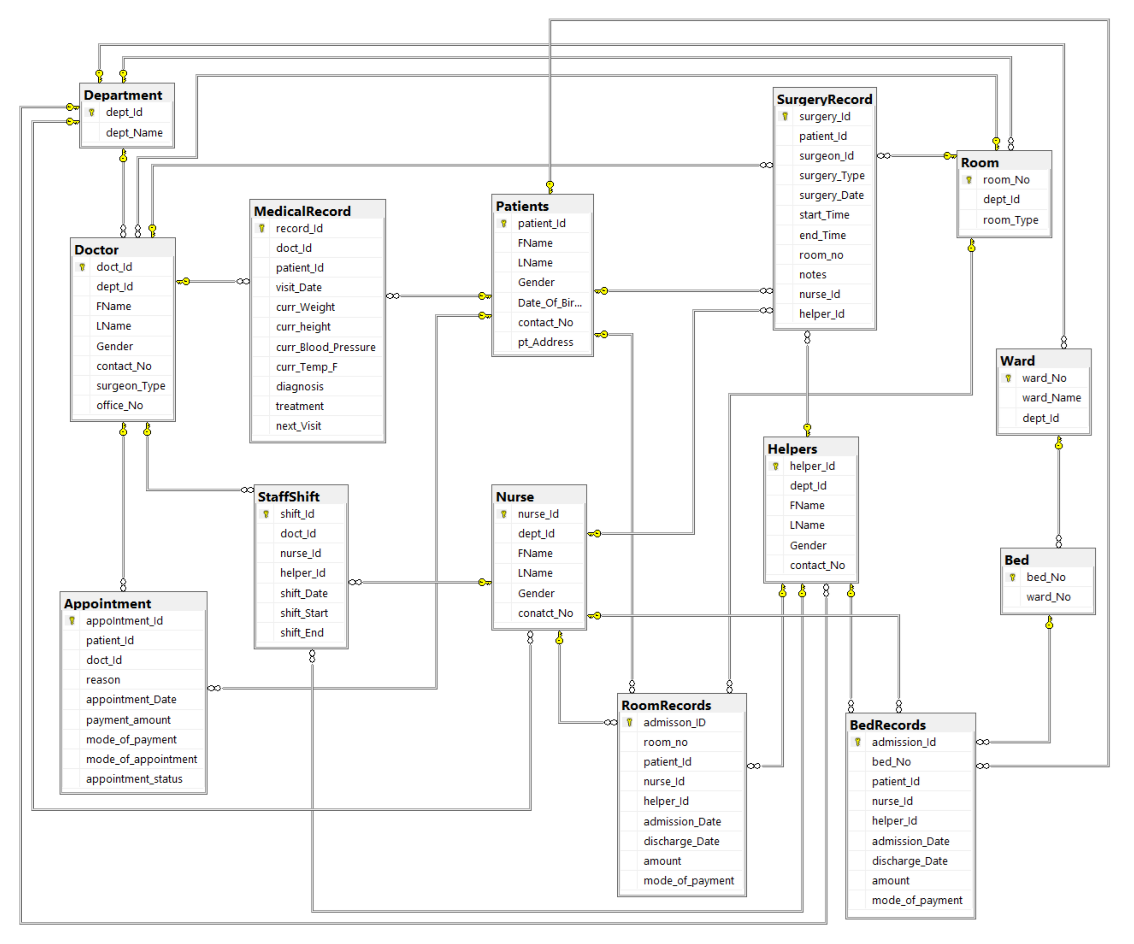

In [17]:
from PIL import Image
import matplotlib.pyplot as plt

image_path = "/kaggle/input/datasets/mshamoonbutt/hospital-management-system/G2_Hospital_Management_Sytem_ERD_final.jpg"
erd_image = Image.open(image_path)

plt.figure(figsize=(18, 12))
plt.imshow(erd_image)
plt.axis("off")
plt.show()

In [18]:
patients_df = tables["Patients"]
medical_records_df = tables["MedicalRecord"]

valid_patient_ids = patients_df["patient_Id"].dropna().unique()

unmatched_records = medical_records_df[
    medical_records_df["patient_Id"].notna()
    & ~medical_records_df["patient_Id"].isin(valid_patient_ids)
]

print("Unmatched MedicalRecord records:", len(unmatched_records))

if unmatched_records.empty:
    print("All non-missing patient IDs match a record in Patients.")
else:
    display(unmatched_records)

Unmatched MedicalRecord records: 0
All non-missing patient IDs match a record in Patients.


In [19]:
doctor_df = tables["Doctor"]
department_df = tables["Department"]

valid_department_ids = department_df["dept_Id"].dropna().unique()

unmatched_doctors = doctor_df[
    doctor_df["dept_Id"].notna()
    & ~doctor_df["dept_Id"].isin(valid_department_ids)
]

print("Unmatched doctor records:", len(unmatched_doctors))

if unmatched_doctors.empty:
    print("All non-missing doctor department IDs match a department.")
else:
    display(unmatched_doctors)


Unmatched doctor records: 0
All non-missing doctor department IDs match a department.


In [20]:
appointments_df = tables["Appointment"]
patients_df = tables["Patients"]

valid_patient_ids = patients_df["patient_Id"].dropna().unique()

unmatched_appointments = appointments_df[
    appointments_df["patient_Id"].notna()
    & ~appointments_df["patient_Id"].isin(valid_patient_ids)
]

print("Unmatched appointment records:", len(unmatched_appointments))

if unmatched_appointments.empty:
    print("All non-missing appointment patient IDs match a patient.")
else:
    display(unmatched_appointments)

Unmatched appointment records: 0
All non-missing appointment patient IDs match a patient.


## Data Overview and Quality Assessment

### Dataset Overview

The Hospital Management System dataset contains 14 tables and 15,543 records covering patients, appointments, medical records, staff, departments, and hospital operations.

### Key Data Quality Findings

**-Duplicates:** No exact duplicate rows identified.

**-Missing values:** Found in Doctor, MedicalRecord, and StaffShift; patterns were investigated before considering any changes.

**-Date inconsistencies:** 74 medical records have a next_Visit date earlier than visit_Date.

**-StaffShift:** Each record contains exactly one populated staff identifier, consistent with role-specific assignments.

### Referential Integrity

Three relationships were checked, with **zero unmatched records:**

**-MedicalRecord.patient_Id → Patients.patient_Id**

**-Doctor.dept_Id → Department.dept_Id**

**-Appointment.patient_Id → Patients.patient_Id**

### Summary

The assessment identified potential data quality issues while confirming consistency in the three relationships tested. Original records were preserved, and no changes were made without sufficient evidence.

These findings establish a foundation for further SQL analysis and Power BI reporting



In [21]:
appointments_df = tables["Appointment"]

appointment_summary = pd.DataFrame({
    "Column Name": appointments_df.columns,
    "Data Type": appointments_df.dtypes.astype(str).values,
    "Missing Values": appointments_df.isnull().sum().values
})

display(appointment_summary)

,Column Name,Data Type,Missing Values
0,appoIntment_Id,int64,0
1,patient_Id,int64,0
2,doct_Id,int64,0
3,reason,object,0
4,appointment_Date,datetime64[ns],0
5,payment_amount,int64,0
6,mode_of_payment,object,0
7,mode_of_appointment,object,0
8,appointment_status,object,0


In [22]:
appointments_df = tables["Appointment"]

display(appointments_df.head())

print("Distinct values in mode_of_payment:")
print(appointments_df["mode_of_payment"].unique())

print("\nDistinct values in mode_of_appointment:")
print(appointments_df["mode_of_appointment"].unique())

print("\nDistinct values in appointment_status:")
print(appointments_df["appointment_status"].unique())

,appoIntment_Id,patient_Id,doct_Id,reason,appointment_Date,payment_amount,mode_of_payment,mode_of_appointment,appointment_status
0,5000,1057,1027,Back Pain,2024-11-27,2139,Insurance,Call,Completed
1,5001,1568,1009,Migraine,2024-09-24,1204,Card,In Person,Completed
2,5002,449,1024,Diabetes,2024-09-07,2474,Digital Wallet,Call,Completed
3,5003,279,1008,Migraine,2025-05-30,1148,Insurance,Call,Completed
4,5004,1089,1001,Hypertension,2024-09-25,2031,Insurance,Online,Cancelled


Distinct values in mode_of_payment:
['Insurance' 'Card' 'Digital Wallet' 'Cash']

Distinct values in mode_of_appointment:
['Call' 'In Person' 'Online']

Distinct values in appointment_status:
['Completed' 'Cancelled' 'Scheduled' 'No-Show']


In [23]:
appointments_df = tables["Appointment"]

print("Payment Amount Summary Statistics:")
display(appointments_df["payment_amount"].describe())

print("Minimum:", appointments_df["payment_amount"].min())
print("Maximum:", appointments_df["payment_amount"].max())
print("Mean:", appointments_df["payment_amount"].mean())
print("Median:", appointments_df["payment_amount"].median())

unusual_payments = appointments_df[
    appointments_df["payment_amount"] <= 0
]

print("Number of zero or negative payment amounts:", len(unusual_payments))

if unusual_payments.empty:
    print("No zero or negative payment amounts found.")
else:
    display(unusual_payments)

Payment Amount Summary Statistics:


count    1000.00000
mean     1663.35400
std       491.97506
min       800.00000
25%      1237.00000
50%      1677.50000
75%      2090.75000
max      2499.00000
Name: payment_amount, dtype: float64

Minimum: 800
Maximum: 2499
Mean: 1663.354
Median: 1677.5
Number of zero or negative payment amounts: 0
No zero or negative payment amounts found.


In [24]:
appointments_df = tables["Appointment"]

today = pd.Timestamp.today().normalize()

print("Earliest appointment date:", appointments_df["appointment_Date"].min())
print("Latest appointment date:", appointments_df["appointment_Date"].max())

missing_dates = appointments_df["appointment_Date"].isna().sum()
print("Number of missing dates:", missing_dates)

future_dates = (
    appointments_df["appointment_Date"].notna()
    & (appointments_df["appointment_Date"] > today)
).sum()

print("Number of future appointment dates:", future_dates)

Earliest appointment date: 2024-07-06 00:00:00
Latest appointment date: 2025-06-29 00:00:00
Number of missing dates: 0
Number of future appointment dates: 0


In [25]:
appointments_df = tables["Appointment"]
patients_df = tables["Patients"]
doctors_df = tables["Doctor"]

valid_patient_ids = patients_df["patient_Id"].dropna().unique()
valid_doctor_ids = doctors_df["doct_Id"].dropna().unique()

unmatched_patients = appointments_df[
    appointments_df["patient_Id"].notna()
    & ~appointments_df["patient_Id"].isin(valid_patient_ids)
]

unmatched_doctors = appointments_df[
    appointments_df["doct_Id"].notna()
    & ~appointments_df["doct_Id"].isin(valid_doctor_ids)
]

print("Unmatched patient ID records:", len(unmatched_patients))
print("Unmatched doctor ID records:", len(unmatched_doctors))

print("\nAppointments with unmatched patient IDs:")
if unmatched_patients.empty:
    print("All non-missing patient IDs match existing patients.")
else:
    display(unmatched_patients)

print("\nAppointments with unmatched doctor IDs:")
if unmatched_doctors.empty:
    print("All non-missing doctor IDs match existing doctors.")
else:
    display(unmatched_doctors)

Unmatched patient ID records: 0
Unmatched doctor ID records: 0

Appointments with unmatched patient IDs:
All non-missing patient IDs match existing patients.

Appointments with unmatched doctor IDs:
All non-missing doctor IDs match existing doctors.


In [26]:
appointments_df = tables["Appointment"]

status_summary = appointments_df["appointment_status"].value_counts(dropna=False)

status_percentages = (
    appointments_df["appointment_status"]
    .value_counts(dropna=False, normalize=True) * 100
)

appointment_status_summary = pd.DataFrame({
    "Status": status_summary.index,
    "Appointment Count": status_summary.values,
    "Percentage (%)": status_percentages.reindex(status_summary.index).values
})

appointment_status_summary["Percentage (%)"] = (
    appointment_status_summary["Percentage (%)"].round(2)
)

display(appointment_status_summary)

,Status,Appointment Count,Percentage (%)
0,Completed,769,76.9
1,No-Show,102,10.2
2,Scheduled,86,8.6
3,Cancelled,43,4.3


In [27]:
appointments_df = tables["Appointment"]

doctor_appointment_counts = (
    appointments_df["doct_Id"]
    .value_counts(dropna=False)
    .reset_index()
)

doctor_appointment_counts.columns = [
    "Doctor ID",
    "Appointment Count"
]

doctor_appointment_counts = doctor_appointment_counts.sort_values(
    by="Appointment Count",
    ascending=False
)

display(doctor_appointment_counts)

,Doctor ID,Appointment Count
0,1027,505
1,1020,110
2,1024,107
3,1001,79
4,1008,60
5,1009,54
6,1002,30
7,1004,29
8,1003,26


In [28]:
print("Distinct non-missing doctor IDs:", appointments_df["doct_Id"].nunique())
print("Missing doctor IDs:", appointments_df["doct_Id"].isna().sum())
print("Total appointment records:", len(appointments_df))

Distinct non-missing doctor IDs: 9
Missing doctor IDs: 0
Total appointment records: 1000


In [29]:
departments_df = tables["Department"]
print(departments_df.columns.tolist())

['dept_Id', 'dept_Name']


In [30]:
appointments_df = tables["Appointment"]
doctors_df = tables["Doctor"]
departments_df = tables["Department"]

appointment_doctors = appointments_df.merge(
    doctors_df[["doct_Id", "dept_Id"]],
    on="doct_Id",
    how="left"
)

appointment_departments = appointment_doctors.merge(
    departments_df,
    on="dept_Id",
    how="left"
)

department_appointment_counts = (
    appointment_departments
    .groupby(["dept_Id", "dept_Name"], dropna=False)
    .size()
    .reset_index(name="Appointment Count")
)

department_appointment_counts = department_appointment_counts.sort_values(
    by="Appointment Count",
    ascending=False
)

display(department_appointment_counts)

,dept_Id,dept_Name,Appointment Count
4,107,General Medicine,505
0,101,Cardiology,164
1,102,Neurology,114
2,105,Pulmonology,110
3,106,Endocrinology,107


In [31]:
print("Total appointments:", len(appointments_df))
print(
    "Appointments counted by department:",
    department_appointment_counts["Appointment Count"].sum()
)

Total appointments: 1000
Appointments counted by department: 1000


In [32]:
medical_records_df = tables["MedicalRecord"]

missing_next_visits = medical_records_df[
    medical_records_df["next_Visit"].isna()
]

print("Records with missing next_Visit dates:", len(missing_next_visits))

invalid_visit_dates = medical_records_df[
    medical_records_df["visit_Date"].notna()
    & medical_records_df["next_Visit"].notna()
    & (medical_records_df["next_Visit"] < medical_records_df["visit_Date"])
]

print("Records where next_Visit is earlier than visit_Date:", len(invalid_visit_dates))

print("\nRecords with missing next_Visit dates:")
display(missing_next_visits[["record_Id", "visit_Date", "next_Visit"]])

print("\nRecords where next_Visit is earlier than visit_Date:")
display(invalid_visit_dates[["record_Id", "visit_Date", "next_Visit"]])

Records with missing next_Visit dates: 1531
Records where next_Visit is earlier than visit_Date: 74

Records with missing next_Visit dates:


,record_Id,visit_Date,next_Visit
4,5,2025-02-06,NaT
5,6,2025-02-06,NaT
8,9,2025-02-06,NaT
10,11,2025-02-06,NaT
16,17,2025-02-06,NaT
...,...,...,...
2991,2992,2024-09-14,NaT
2992,2993,2024-10-17,NaT
2993,2994,2024-10-19,NaT
2998,2999,2024-12-16,NaT



Records where next_Visit is earlier than visit_Date:


,record_Id,visit_Date,next_Visit
48,49,2025-02-06,2025-01-08
126,127,2025-02-06,2025-01-08
131,132,2025-02-06,2025-01-07
144,145,2025-02-06,2025-01-08
208,209,2025-02-06,2025-01-07
...,...,...,...
2805,2806,2025-12-02,2025-06-15
2880,2881,2025-01-29,2025-01-08
2965,2966,2025-10-03,2025-06-23
2966,2967,2025-11-02,2025-07-19


In [33]:
print("Most frequent visit_Date values:")
display(
    invalid_visit_dates["visit_Date"]
    .value_counts()
    .head(10)
    .reset_index()
    .rename(columns={
        "visit_Date": "Visit Date",
        "count": "Record Count"
    })
)

print("Most frequent next_Visit values:")
display(
    invalid_visit_dates["next_Visit"]
    .value_counts()
    .head(10)
    .reset_index()
    .rename(columns={
        "next_Visit": "Next Visit Date",
        "count": "Record Count"
    })
)

print("Potentially inconsistent records:")
display(
    invalid_visit_dates[
        ["record_Id", "visit_Date", "next_Visit"]
    ].sort_values(by="visit_Date")
)

Most frequent visit_Date values:


,Visit Date,Record Count
0,2025-02-06,14
1,2025-09-01,5
2,2025-09-04,4
3,2025-08-04,4
4,2025-10-02,4
5,2025-11-02,4
6,2025-11-01,3
7,2025-08-01,3
8,2025-12-02,3
9,2025-10-03,3


Most frequent next_Visit values:


,Next Visit Date,Record Count
0,2025-01-08,14
1,2025-01-07,9
2,2025-04-07,4
3,2025-03-07,3
4,2025-06-16,3
5,2025-07-19,3
6,2025-07-18,2
7,2025-02-07,2
8,2025-07-20,2
9,2025-06-26,2


Potentially inconsistent records:


,record_Id,visit_Date,next_Visit
2258,2259,2025-01-13,2025-01-08
2880,2881,2025-01-29,2025-01-08
1767,1768,2025-02-04,2025-01-08
855,856,2025-02-06,2025-01-07
689,690,2025-02-06,2025-01-08
...,...,...,...
1619,1620,2025-12-02,2025-06-23
2805,2806,2025-12-02,2025-06-15
1674,1675,2025-12-02,2025-06-18
2358,2359,2025-12-03,2025-07-19


In [34]:
visit_date_analysis = invalid_visit_dates[
    ["record_Id", "visit_Date", "next_Visit"]
].copy()

visit_date_analysis["Days Difference"] = (
    visit_date_analysis["next_Visit"] - visit_date_analysis["visit_Date"]
).dt.days

display(visit_date_analysis)

print("Minimum day difference:", visit_date_analysis["Days Difference"].min())
print("Maximum day difference:", visit_date_analysis["Days Difference"].max())
print("Median day difference:", visit_date_analysis["Days Difference"].median())

day_difference_counts = (
    visit_date_analysis["Days Difference"]
    .value_counts()
)

print("\nMost frequent day difference(s):")
display(
    day_difference_counts[
        day_difference_counts == day_difference_counts.max()
    ].rename("Record Count").reset_index()
)

,record_Id,visit_Date,next_Visit,Days Difference
48,49,2025-02-06,2025-01-08,-29
126,127,2025-02-06,2025-01-08,-29
131,132,2025-02-06,2025-01-07,-30
144,145,2025-02-06,2025-01-08,-29
208,209,2025-02-06,2025-01-07,-30
...,...,...,...,...
2805,2806,2025-12-02,2025-06-15,-170
2880,2881,2025-01-29,2025-01-08,-21
2965,2966,2025-10-03,2025-06-23,-102
2966,2967,2025-11-02,2025-07-19,-106


Minimum day difference: -267
Maximum day difference: -5
Median day difference: -53.0

Most frequent day difference(s):


,Days Difference,Record Count
0,-29,7
1,-30,7


## MedicalRecord Date Review

**-Records reviewed:** 3,000

**-Potential date inconsistencies:** 74 (2.47%)

**-Day differences:** Ranged from -5 to -267 days

**-Median difference:** -53 days

**-Most frequent differences:** -29 and -30 days, with 7 records each

These records have a **next_Visit** date earlier than the corresponding **visit_Date**. The pattern requires further investigation before determining whether the dates are incorrect. No dates were changed, and the original data was preserved.

In [35]:
total_records = len(invalid_visit_dates)

unique_patients = invalid_visit_dates["patient_Id"].nunique()

print("Total flagged medical records:", total_records)
print("Number of unique patients:", unique_patients)

records_per_patient = (
    invalid_visit_dates["patient_Id"]
    .value_counts()
)

patients_with_multiple_records = records_per_patient[
    records_per_patient > 1
]

print(
    "\nNumber of patients with multiple flagged records:",
    len(patients_with_multiple_records)
)

if patients_with_multiple_records.empty:
    print("No patients have more than one flagged record.")
else:
    display(
        patients_with_multiple_records
        .rename_axis("patient_Id")
        .reset_index(name="Flagged Record Count")
    )

Total flagged medical records: 74
Number of unique patients: 74

Number of patients with multiple flagged records: 0
No patients have more than one flagged record.


### Patient-Level Review of Potential Date Inconsistencies

**-Flagged medical records:** 74

**-Unique patients affected:** 74

**-Patients with multiple flagged records:** 0

Each of the 74 potentially inconsistent medical records belongs to a different patient. No patient has more than one flagged record. This suggests the issue is not concentrated among a small group of patients. The cause of the date inconsistencies remains unknown, and no records or dates were modified.

In [36]:
all_records = medical_records_df[["visit_Date"]].copy()
flagged_records = invalid_visit_dates[["visit_Date"]].copy()

all_records["Month"] = all_records["visit_Date"].dt.month
flagged_records["Month"] = flagged_records["visit_Date"].dt.month

monthly_total = all_records["Month"].value_counts().sort_index()

monthly_flagged = flagged_records["Month"].value_counts().sort_index()

monthly_comparison = pd.DataFrame({
    "Total Medical Records": monthly_total,
    "Flagged Records": monthly_flagged
}).fillna(0)

monthly_comparison = monthly_comparison.astype(int)

total_records = len(medical_records_df)
flagged_total = len(invalid_visit_dates)

monthly_comparison["All Records (%)"] = (
    monthly_comparison["Total Medical Records"] / total_records * 100
)

monthly_comparison["Flagged Records (%)"] = (
    monthly_comparison["Flagged Records"] / flagged_total * 100
)

monthly_comparison["Monthly Flagged Rate (%)"] = (
    monthly_comparison["Flagged Records"]
    / monthly_comparison["Total Medical Records"] * 100
)

monthly_comparison.index.name = "Month"
display(monthly_comparison.round(2).reset_index())

,Month,Total Medical Records,Flagged Records,All Records (%),Flagged Records (%),Monthly Flagged Rate (%)
0,1,180,2,6.00,2.70,1.11
1,2,1079,16,35.97,21.62,1.48
2,3,168,3,5.60,4.05,1.79
3,4,174,5,5.80,6.76,2.87
4,5,172,0,5.73,0.00,0.00
5,6,175,2,5.83,2.70,1.14
6,7,177,2,5.90,2.70,1.13
7,8,156,7,5.20,9.46,4.49
8,9,173,11,5.77,14.86,6.36
9,10,180,10,6.00,13.51,5.56


In [37]:
date_analysis = medical_records_df[["visit_Date"]].copy()

date_analysis["Year"] = date_analysis["visit_Date"].dt.year
date_analysis["Month"] = date_analysis["visit_Date"].dt.month

year_month_counts = (
    date_analysis
    .dropna(subset=["visit_Date"])
    .groupby(["Year", "Month"])
    .size()
    .reset_index(name="Record Count")
    .sort_values(["Year", "Month"])
)

print("Medical records by year and month:")
display(year_month_counts)

february_counts = year_month_counts[
    year_month_counts["Month"] == 2
].copy()

print("\nFebruary record counts by year:")
display(february_counts)

if not february_counts.empty:
    print("Number of years with February records:", len(february_counts))
    print("Highest February count:", february_counts["Record Count"].max())
    print(
        "Year with highest February count:",
        february_counts.loc[
            february_counts["Record Count"].idxmax(), "Year"
        ]
    )

Medical records by year and month:


,Year,Month,Record Count
0,2024,1,46
1,2024,2,62
2,2024,3,40
3,2024,4,48
4,2024,5,149
5,2024,6,155
6,2024,7,154
7,2024,8,140
8,2024,9,152
9,2024,10,158



February record counts by year:


,Year,Month,Record Count
1,2024,2,62
13,2025,2,1017


Number of years with February records: 2
Highest February count: 1017
Year with highest February count: 2025


In [38]:
february_2025 = medical_records_df[
    (medical_records_df["visit_Date"].dt.year == 2025)
    & (medical_records_df["visit_Date"].dt.month == 2)
].copy()

daily_counts = (
    february_2025["visit_Date"]
    .dt.day
    .value_counts()
    .sort_index()
    .reset_index()
)

daily_counts.columns = ["Day of February", "Record Count"]

print("Medical records per day in February 2025:")
display(daily_counts)

print("\nTotal records in February 2025:", len(february_2025))
print("Earliest visit date:", february_2025["visit_Date"].min())
print("Latest visit date:", february_2025["visit_Date"].max())

Medical records per day in February 2025:


,Day of February,Record Count
0,1,4
1,2,7
2,3,2
3,4,8
4,6,906
5,13,2
6,14,4
7,15,10
8,16,3
9,17,9



Total records in February 2025: 1017
Earliest visit date: 2025-02-01 00:00:00
Latest visit date: 2025-02-28 00:00:00


In [39]:
february_6_records = medical_records_df[
    medical_records_df["visit_Date"].dt.normalize()
    == pd.Timestamp("2025-02-06")
].copy()

print("Total records on February 6, 2025:", len(february_6_records))

print(
    "Number of unique patients:",
    february_6_records["patient_Id"].nunique()
)

unique_value_summary = pd.DataFrame({
    "Column": february_6_records.columns,
    "Unique Values": [
        february_6_records[column].nunique()
        for column in february_6_records.columns
    ],
    "Total Records": len(february_6_records),
    "Most Frequent Value Count": [
        february_6_records[column].value_counts().max()
        if february_6_records[column].notna().any()
        else 0
        for column in february_6_records.columns
    ]
})

unique_value_summary["Most Frequent Value (%)"] = (
    unique_value_summary["Most Frequent Value Count"]
    / len(february_6_records) * 100
    if len(february_6_records) > 0
    else 0
)

unique_value_summary = unique_value_summary.sort_values(
    by="Most Frequent Value (%)",
    ascending=False
)

display(unique_value_summary.round(2))

print("\nRecords dated February 6, 2025:")
display(february_6_records)

Total records on February 6, 2025: 906
Number of unique patients: 726


,Column,Unique Values,Total Records,Most Frequent Value Count,Most Frequent Value (%)
3,visit_Date,1,906,906,100.00
6,curr_Blood_Pressure,2,906,789,87.09
1,doct_Id,9,906,426,47.02
9,treatment,8,906,205,22.63
8,diagnosis,8,906,205,22.63
10,next_Visit,54,906,16,1.77
7,curr_Temp_F,267,906,11,1.21
5,curr_height,817,906,4,0.44
2,patient_Id,726,906,4,0.44
4,curr_Weight,826,906,3,0.33



Records dated February 6, 2025:


,record_Id,doct_Id,patient_Id,visit_Date,curr_Weight,curr_height,curr_Blood_Pressure,curr_Temp_F,diagnosis,treatment,next_Visit
0,1,1027,1057,2025-02-06,62.89,156.21,120/80,98.46,Lumbar Strain,"Physical Therapy, NSAIDs",2025-06-22
1,2,1009,1568,2025-02-06,50.74,184.41,120/80,97.39,Migraine Headache,"Triptans, Rest",2025-06-20
2,3,1024,449,2025-02-06,83.15,156.18,120/80,97.75,Type 2 Diabetes,"Metformin, Diet Control",2025-04-07
3,4,1008,279,2025-02-06,56.80,146.96,120/80,97.81,Migraine Headache,"Triptans, Rest",2025-07-31
4,5,1001,1089,2025-02-06,77.97,160.82,150/95,98.75,Essential Hypertension,"ACE Inhibitors, Lifestyle Changes",NaT
...,...,...,...,...,...,...,...,...,...,...,...
901,902,1003,347,2025-02-06,69.35,181.77,150/95,97.16,Essential Hypertension,"ACE Inhibitors, Lifestyle Changes",NaT
902,903,1020,920,2025-02-06,53.72,140.99,120/80,98.89,Bronchial Asthma,Inhaled Corticosteroids,2025-04-07
903,904,1027,1105,2025-02-06,61.65,159.45,120/80,97.68,Angina Pectoris,"Nitroglycerin, Beta Blockers",2025-06-29
904,905,1001,422,2025-02-06,84.96,145.39,120/80,97.63,Angina Pectoris,"Nitroglycerin, Beta Blockers",2025-06-13


In [40]:
target_date = pd.Timestamp("2025-02-06")

feb6_mask = medical_records_df["visit_Date"].dt.normalize() == target_date

feb6_records = medical_records_df.loc[feb6_mask]
other_records = medical_records_df.loc[~feb6_mask]

def summarize_blood_pressure(data, group_name):
    blood_pressure = data["curr_Blood_Pressure"]

    counts = blood_pressure.value_counts()

    total_records = len(data)
    unique_values = blood_pressure.nunique()

    if counts.empty:
        most_frequent_value = None
        most_frequent_count = 0
        most_frequent_percentage = 0
    else:
        most_frequent_value = counts.index[0]
        most_frequent_count = counts.iloc[0]
        most_frequent_percentage = (
            most_frequent_count / total_records * 100
            if total_records > 0 else 0
        )

    return {
        "Group": group_name,
        "Total Records": total_records,
        "Most Frequent Blood Pressure": most_frequent_value,
        "Most Frequent Count": most_frequent_count,
        "Most Frequent Percentage (%)": round(most_frequent_percentage, 2),
        "Unique Blood Pressure Values": unique_values
    }

comparison = pd.DataFrame([
    summarize_blood_pressure(feb6_records, "February 6, 2025"),
    summarize_blood_pressure(other_records, "All Other Records")
])

display(comparison)

,Group,Total Records,Most Frequent Blood Pressure,Most Frequent Count,Most Frequent Percentage (%),Unique Blood Pressure Values
0,"February 6, 2025",906,120/80,789,87.09,2
1,All Other Records,2094,120/80,2074,99.04,2


# Phase 2 — Appointment and Medical Record Analysis

## 1. Appointment Status

The dataset contains 1,000 appointment records.

| Appointment Status | Count | Percentage |
|---|---:|---:|
| Completed | 769 | 76.9% |
| No-show | 102 | 10.2% |
| Scheduled | 86 | 8.6% |
| Cancelled | 43 | 4.3% |

**Finding:** Most recorded appointments are marked as completed (76.9%). No-shows account for 10.2% of appointments, representing a potential area for further operational investigation.

## 2. Department Distribution

| Department | Appointments | Percentage |
|---|---:|---:|
| General Medicine | 505 | 50.5% |
| Cardiology | 164 | 16.4% |
| Neurology | 114 | 11.4% |
| Pulmonology | 110 | 11.0% |
| Endocrinology | 107 | 10.7% |

**Finding:** General Medicine accounts for approximately half of the recorded appointments, making it the most represented department in this dataset. These counts describe appointment distribution but do not establish department performance or staffing requirements.

## 3. Medical Record Date Anomaly

The dataset contains 1,017 medical records dated February 2025. Of these, 906 (approximately 89.1%) have a visit date of February 6, 2025.

**Finding:** Medical records are unusually concentrated on a single date. The available analysis has not established the cause, so this pattern is documented as an unresolved data anomaly rather than attributed to a specific operational issue.

## Summary

The appointment analysis identified the distribution of appointment outcomes and departmental activity. The medical-record analysis also identified an unusual concentration of records on February 6, 2025.

Further analysis will focus on distinct patient and operational questions, using existing findings where possible to avoid duplicating completed work.

In [41]:
medical_records_df = tables["MedicalRecord"].copy()

complete_records = medical_records_df[
    medical_records_df["diagnosis"].notna()
    & medical_records_df["treatment"].notna()
    & medical_records_df["doct_Id"].notna()
    & medical_records_df["patient_Id"].notna()
]

doctor_documentation = (
    complete_records.groupby("doct_Id")["patient_Id"]
    .nunique()
    .sort_values(ascending=False)
    .reset_index(name="Patients with Diagnosis and Treatment")
)

display(doctor_documentation.head(10))

,doct_Id,Patients with Diagnosis and Treatment
0,1027,433
1,1020,114
2,1024,99
3,1001,80
4,1008,67
5,1009,59
6,1004,36
7,1002,34
8,1003,28
9,1202,12


In [42]:
doctor_df = tables["Doctor"].copy()
department_df = tables["Department"].copy()

doctor_1027 = doctor_df[doctor_df["doct_Id"] == 1027]

display(
    doctor_1027.merge(
        department_df,
        on="dept_Id",
        how="left",
        suffixes=("_doctor", "_department")
    )
)

,doct_Id,dept_Id,FName,LName,Gender,contact_No,surgeon_Type,office_No,dept_Name
0,1027,107,Dr. Raza,Hasnain,M,+92 3348510548,NaN,96.0,General Medicine


In [43]:
medical_records_df = tables["MedicalRecord"].copy()

doctor_1027_records = medical_records_df[
    (medical_records_df["doct_Id"] == 1027)
    & medical_records_df["diagnosis"].notna()
    & medical_records_df["patient_Id"].notna()
].copy()

diagnosis_summary = (
    doctor_1027_records
    .groupby("diagnosis")
    .agg(
        Record_Count=("record_Id", "count"),
        Unique_Patients=("patient_Id", "nunique")
    )
    .sort_values(
        by="Unique_Patients",
        ascending=False
    )
    .reset_index()
)

display(diagnosis_summary.head(10))

,diagnosis,Record_Count,Unique_Patients
0,General Checkup,211,210
1,Lumbar Strain,86,86
2,Viral Fever,84,84
3,Angina Pectoris,51,51
4,Hypothyroidism,1,1
5,Nephrolithiasis,1,1
6,Osteoarthritis,1,1
7,Routine Health Check,1,1


In [44]:
for table_name in ["StaffShift", "Doctor", "Nurse", "Helpers", "Department"]:
    df = tables[table_name]

    print(f"\n--- {table_name} ---")
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    display(df.head(3))


--- StaffShift ---
Shape: (2058, 7)
Columns: ['shift_Id', 'doct_Id', 'nurse_Id', 'helper_Id', 'shift_Date', 'shift_Start', 'shift_End']


,shift_Id,doct_Id,nurse_Id,helper_Id,shift_Date,shift_Start,shift_End
0,70001,1147.0,NaN,NaN,2025-05-19,08:00:00,12:00:00
1,70002,1149.0,NaN,NaN,2025-05-20,14:00:00,16:00:00
2,70003,1148.0,NaN,NaN,2025-05-21,06:00:00,14:00:00



--- Doctor ---
Shape: (400, 8)
Columns: ['doct_Id', 'dept_Id', 'FName', 'LName', 'Gender', 'contact_No', 'surgeon_Type', 'office_No']


,doct_Id,dept_Id,FName,LName,Gender,contact_No,surgeon_Type,office_No
0,1001,101,Dr. Najeeb,Basir,M,+92 3226702403,NaN,1.0
1,1002,101,Dr. Kamran,Ahmed,M,+92 3509542256,NaN,1.0
2,1003,101,Dr. Sheikh,M. Ilyas,M,+92 3091755242,NaN,2.0



--- Nurse ---
Shape: (500, 6)
Columns: ['nurse_Id', 'dept_Id', 'FName', 'LName', 'Gender', 'conatct_No']


,nurse_Id,dept_Id,FName,LName,Gender,conatct_No
0,3001,101,Daniyal,Gujjar,M,+92 3547828228
1,3002,101,Junaid,Qazi,M,+92 3255737654
2,3003,101,Bisma,Chaudhry,F,+92 3354368875



--- Helpers ---
Shape: (1100, 6)
Columns: ['helper_Id', 'dept_Id', 'FName', 'LName', 'Gender', 'contact_No']


,helper_Id,dept_Id,FName,LName,Gender,contact_No
0,8001,106,Qamar,Jan,M,+92 3181605664
1,8002,124,Liaqat,Dar,M,+92 3194325077
2,8003,113,Haris,Mughal,M,+92 3118898494



--- Department ---
Shape: (31, 2)
Columns: ['dept_Id', 'dept_Name']


,dept_Id,dept_Name
0,101,Cardiology
1,102,Neurology
2,103,Gastroenterology


In [45]:
department_staffing = (
    tables["Department"][["dept_Id", "dept_Name"]]
    .merge(
        tables["Doctor"].groupby("dept_Id")["doct_Id"]
        .nunique().rename("Doctor_Count"),
        on="dept_Id", how="left"
    )
    .merge(
        tables["Nurse"].groupby("dept_Id")["nurse_Id"]
        .nunique().rename("Nurse_Count"),
        on="dept_Id", how="left"
    )
    .merge(
        tables["Helpers"].groupby("dept_Id")["helper_Id"]
        .nunique().rename("Helper_Count"),
        on="dept_Id", how="left"
    )
    .fillna({
        "Doctor_Count": 0,
        "Nurse_Count": 0,
        "Helper_Count": 0
    })
)

staffing_columns = ["Doctor_Count", "Nurse_Count", "Helper_Count"]
department_staffing[staffing_columns] = (
    department_staffing[staffing_columns].astype(int)
)

department_staffing["Nurses_per_Doctor"] = (
    department_staffing["Nurse_Count"]
    / department_staffing["Doctor_Count"].replace(0, float("nan"))
)

department_staffing["Helpers_per_Doctor"] = (
    department_staffing["Helper_Count"]
    / department_staffing["Doctor_Count"].replace(0, float("nan"))
)

display(
    department_staffing.sort_values(
        "Doctor_Count", ascending=False
    )
)

,dept_Id,dept_Name,Doctor_Count,Nurse_Count,Helper_Count,Nurses_per_Doctor,Helpers_per_Doctor
6,107,General Medicine,52,40,49,0.769231,0.942308
29,130,Critical Care,51,55,30,1.078431,0.588235
20,121,Emergency Medicine,47,40,27,0.851064,0.574468
16,117,Surgery,38,50,35,1.315789,0.921053
28,129,Family Medicine,37,15,29,0.405405,0.783784
26,127,Homeopathy,20,5,27,0.250000,1.350000
15,116,ENT,16,10,38,0.625000,2.375000
7,108,Pediatrics,14,20,35,1.428571,2.500000
22,123,Rehabilitation,10,10,33,1.000000,3.300000
30,131,Geriatrics,8,31,43,3.875000,5.375000


In [46]:
print("Departments ranked by nurse headcount:")
display(
    department_staffing[
        ["dept_Name", "Nurse_Count"]
    ].sort_values("Nurse_Count", ascending=False)
)

print("Departments ranked by helper headcount:")
display(
    department_staffing[
        ["dept_Name", "Helper_Count"]
    ].sort_values("Helper_Count", ascending=False)
)

Departments ranked by nurse headcount:


,dept_Name,Nurse_Count
29,Critical Care,55
16,Surgery,50
6,General Medicine,40
20,Emergency Medicine,40
30,Geriatrics,31
0,Cardiology,29
1,Neurology,20
4,Pulmonology,20
7,Pediatrics,20
28,Family Medicine,15


Departments ranked by helper headcount:


,dept_Name,Helper_Count
14,Urology,50
6,General Medicine,49
12,Psychiatry,45
23,Hematology,43
30,Geriatrics,43
4,Pulmonology,41
11,Dermatology,41
27,Sexology,40
24,Immunology,40
13,Psychology,38


### Department Staffing Distribution

The department-level staffing analysis shows substantial variation in recorded nurse and helper headcounts across the hospital.

- **Highest nurse headcount:** Critical Care (55), followed by Surgery (50).
- **Highest helper headcount:** Urology (50), followed by General Medicine (49).
- **Lowest nurse headcount:** Endocrinology has no nurses recorded, while several departments have five.
- **Staffing composition varies:** Some departments with relatively few nurses have comparatively high helper counts.

These results describe the distribution of staff recorded in the dataset. They do not establish whether staffing levels are adequate because patient demand, staff schedules, employment status, and department-specific responsibilities have not yet been considered. Endocrinology's zero nurse count should be validated before interpreting it as a true staffing condition.

In [47]:
appointment_df = tables["Appointment"].copy()
doctor_df = tables["Doctor"][["doct_Id", "dept_Id"]].copy()

appointment_activity = (
    appointment_df
    .merge(doctor_df, on="doct_Id", how="left")
    .groupby("dept_Id")
    .size()
    .reset_index(name="Appointments")
)

medical_records_df = tables["MedicalRecord"].copy()

medical_record_activity = (
    medical_records_df
    .merge(doctor_df, on="doct_Id", how="left")
    .groupby("dept_Id")
    .size()
    .reset_index(name="Medical_Record_Count")
)

department_activity_summary = (
    department_staffing
    .merge(appointment_activity, on="dept_Id", how="left")
    .merge(medical_record_activity, on="dept_Id", how="left")
)

department_activity_summary[
    ["Appointments", "Medical_Record_Count"]
] = department_activity_summary[
    ["Appointments", "Medical_Record_Count"]
].fillna(0).astype(int)

display(
    department_activity_summary[
        [
            "dept_Name",
            "Doctor_Count",
            "Nurse_Count",
            "Helper_Count",
            "Appointments",
            "Medical_Record_Count"
        ]
    ].sort_values("Appointments", ascending=False)
)

,dept_Name,Doctor_Count,Nurse_Count,Helper_Count,Appointments,Medical_Record_Count
6,General Medicine,52,40,49,505,714
0,Cardiology,7,29,34,164,195
1,Neurology,5,20,32,114,149
4,Pulmonology,4,20,41,110,134
5,Endocrinology,3,0,38,107,105
2,Gastroenterology,3,15,29,0,10
3,Nephrology,4,15,37,0,20
7,Pediatrics,14,20,35,0,64
8,Orthopedics,5,15,29,0,20
9,Gynecology,8,15,28,0,52


In [48]:
medical_records_df = tables["MedicalRecord"].copy()
doctor_df = tables["Doctor"][["doct_Id", "dept_Id"]].copy()

medical_record_join_check = medical_records_df.merge(
    doctor_df,
    on="doct_Id",
    how="left",
    indicator=True
)

print("Total medical records:", len(medical_record_join_check))
print("\nDoctor match status:")
display(medical_record_join_check["_merge"].value_counts())

print("\nMedical records by department ID:")
display(
    medical_record_join_check["dept_Id"]
    .value_counts(dropna=False)
    .rename_axis("dept_Id")
    .reset_index(name="Medical_Record_Count")
    .sort_values("Medical_Record_Count", ascending=False)
)

Total medical records: 3000

Doctor match status:


_merge
both          3000
left_only        0
right_only       0
Name: count, dtype: int64


Medical records by department ID:


,dept_Id,Medical_Record_Count
0,107,714
1,130,268
2,121,249
3,117,199
4,129,196
5,101,195
6,102,149
7,105,134
8,106,105
9,127,81


In [49]:
department_activity_summary = (
    department_staffing
    .drop(columns=["Appointments", "Medical_Record_Count"], errors="ignore")
    .merge(appointment_activity, on="dept_Id", how="left")
    .merge(
        medical_record_join_check.groupby("dept_Id")
        .size()
        .reset_index(name="Medical_Record_Count"),
        on="dept_Id",
        how="left"
    )
)

display(
    department_activity_summary[
        [
            "dept_Name",
            "Doctor_Count",
            "Nurse_Count",
            "Helper_Count",
            "Appointments",
            "Medical_Record_Count"
        ]
    ].sort_values("Appointments", ascending=False)
)

,dept_Name,Doctor_Count,Nurse_Count,Helper_Count,Appointments,Medical_Record_Count
6,General Medicine,52,40,49,505.0,714
0,Cardiology,7,29,34,164.0,195
1,Neurology,5,20,32,114.0,149
4,Pulmonology,4,20,41,110.0,134
5,Endocrinology,3,0,38,107.0,105
2,Gastroenterology,3,15,29,NaN,10
3,Nephrology,4,15,37,NaN,20
7,Pediatrics,14,20,35,NaN,64
8,Orthopedics,5,15,29,NaN,20
9,Gynecology,8,15,28,NaN,52


In [50]:
staff_shift = tables["StaffShift"].copy()

print("Total shift records:", len(staff_shift))
print("\nMissing values:")
display(staff_shift.isna().sum().to_frame("Missing_Count"))

print("\nShift date range:")
print("Earliest:", staff_shift["shift_Date"].min())
print("Latest:", staff_shift["shift_Date"].max())

print("\nShift start times:")
display(staff_shift["shift_Start"].value_counts().head(10))

print("\nShift end times:")
display(staff_shift["shift_End"].value_counts().head(10))

Total shift records: 2058

Missing values:


,Missing_Count
shift_Id,0
doct_Id,1000
nurse_Id,1558
helper_Id,1558
shift_Date,0
shift_Start,0
shift_End,0



Shift date range:
Earliest: 2025-05-19 00:00:00
Latest: 2025-06-02 00:00:00

Shift start times:


shift_Start
08:00:00    994
20:00:00    549
14:00:00    334
06:00:00     39
07:00:00     26
15:00:00     26
19:00:00     26
23:00:00     26
22:00:00     18
18:00:00     11
Name: count, dtype: int64


Shift end times:


shift_End
08:00:00    549
16:00:00    543
20:00:00    460
22:00:00    333
14:00:00     39
03:00:00     26
23:00:00     26
15:00:00     26
07:00:00     26
06:00:00     18
Name: count, dtype: int64

In [51]:
staff_shift = tables["StaffShift"].copy()

staff_shift["shift_Start"] = pd.to_timedelta(
    staff_shift["shift_Start"].astype(str)
)
staff_shift["shift_End"] = pd.to_timedelta(
    staff_shift["shift_End"].astype(str)
)

staff_shift["Shift_Duration_Hours"] = (
    staff_shift["shift_End"] - staff_shift["shift_Start"]
).dt.total_seconds() / 3600

staff_shift.loc[
    staff_shift["Shift_Duration_Hours"] < 0,
    "Shift_Duration_Hours"
] += 24

print("Shift duration summary (hours):")
display(staff_shift["Shift_Duration_Hours"].describe())

print("\nShift duration counts:")
display(
    staff_shift["Shift_Duration_Hours"]
    .value_counts()
    .sort_index()
    .rename_axis("Duration_Hours")
    .reset_index(name="Shift_Count")
)

Shift duration summary (hours):


count    2058.000000
mean        9.938776
std         2.010701
min         2.000000
25%         8.000000
50%         8.000000
75%        12.000000
max        12.000000
Name: Shift_Duration_Hours, dtype: float64


Shift duration counts:


,Duration_Hours,Shift_Count
0,2.0,1
1,4.0,1
2,8.0,1056
3,12.0,1000


In [52]:
staff_shift = tables["StaffShift"].copy()

staff_shift["Staff_Role"] = "Unknown"

staff_shift.loc[
    staff_shift["doct_Id"].notna(), "Staff_Role"
] = "Doctor"

staff_shift.loc[
    staff_shift["nurse_Id"].notna(), "Staff_Role"
] = "Nurse"

staff_shift.loc[
    staff_shift["helper_Id"].notna(), "Staff_Role"
] = "Helper"

daily_staffing = (
    staff_shift
    .groupby(["shift_Date", "Staff_Role"])
    .size()
    .unstack(fill_value=0)
    .reset_index()
    .sort_values("shift_Date")
)

display(daily_staffing)

Staff_Role,shift_Date,Doctor,Helper,Nurse
0,2025-05-19,71,34,34
1,2025-05-20,71,34,34
2,2025-05-21,71,34,34
3,2025-05-22,71,34,34
4,2025-05-23,71,34,34
5,2025-05-24,71,33,33
6,2025-05-25,71,33,33
7,2025-05-26,71,33,33
8,2025-05-27,70,33,33
9,2025-05-28,70,33,33


In [53]:
shift_df = tables["StaffShift"].copy()
doctor_df = tables["Doctor"][["doct_Id", "dept_Id"]].copy()
nurse_df = tables["Nurse"][["nurse_Id", "dept_Id"]].copy()
helper_df = tables["Helpers"][["helper_Id", "dept_Id"]].copy()
department_df = tables["Department"][["dept_Id", "dept_Name"]].copy()

shift_df["Staff_Role"] = "Unknown"
shift_df.loc[shift_df["doct_Id"].notna(), "Staff_Role"] = "Doctor"
shift_df.loc[shift_df["nurse_Id"].notna(), "Staff_Role"] = "Nurse"
shift_df.loc[shift_df["helper_Id"].notna(), "Staff_Role"] = "Helper"

shift_df = shift_df.merge(
    doctor_df.rename(columns={"doct_Id": "Staff_ID", "dept_Id": "Staff_Department"}),
    left_on="doct_Id",
    right_on="Staff_ID",
    how="left"
)

shift_df = shift_df.merge(
    nurse_df.rename(columns={"nurse_Id": "Staff_ID", "dept_Id": "Nurse_Department"}),
    left_on="nurse_Id",
    right_on="Staff_ID",
    how="left",
    suffixes=("", "_nurse")
)

shift_df = shift_df.merge(
    helper_df.rename(columns={"helper_Id": "Staff_ID", "dept_Id": "Helper_Department"}),
    left_on="helper_Id",
    right_on="Staff_ID",
    how="left",
    suffixes=("", "_helper")
)

shift_df["dept_Id"] = shift_df["Staff_Department"]
shift_df.loc[shift_df["Staff_Role"] == "Nurse", "dept_Id"] = (
    shift_df.loc[shift_df["Staff_Role"] == "Nurse", "Nurse_Department"]
)
shift_df.loc[shift_df["Staff_Role"] == "Helper", "dept_Id"] = (
    shift_df.loc[shift_df["Staff_Role"] == "Helper", "Helper_Department"]
)

shift_df = shift_df.merge(department_df, on="dept_Id", how="left")

print("Total shift records:", len(shift_df))
print("\nStaff roles:")
print(shift_df["Staff_Role"].value_counts(dropna=False))

print("\nMissing department assignments by role:")
print(shift_df.groupby("Staff_Role")["dept_Name"].apply(
    lambda s: s.isna().sum()
))

print("\nSample linked shifts:")
display(
    shift_df[
        ["shift_Id", "shift_Date", "shift_Start", "shift_End",
         "Staff_Role", "dept_Id", "dept_Name"]
    ].head(10)
)

Total shift records: 2058

Staff roles:
Staff_Role
Doctor    1058
Nurse      500
Helper     500
Name: count, dtype: int64

Missing department assignments by role:
Staff_Role
Doctor    0
Helper    0
Nurse     0
Name: dept_Name, dtype: int64

Sample linked shifts:


,shift_Id,shift_Date,shift_Start,shift_End,Staff_Role,dept_Id,dept_Name
0,70001,2025-05-19,08:00:00,12:00:00,Doctor,117.0,Surgery
1,70002,2025-05-20,14:00:00,16:00:00,Doctor,117.0,Surgery
2,70003,2025-05-21,06:00:00,14:00:00,Doctor,117.0,Surgery
3,70004,2025-05-22,14:00:00,22:00:00,Doctor,117.0,Surgery
4,70005,2025-05-23,18:00:00,02:00:00,Doctor,117.0,Surgery
5,70006,2025-05-24,22:00:00,06:00:00,Doctor,117.0,Surgery
6,70007,2025-05-25,08:00:00,16:00:00,Doctor,117.0,Surgery
7,70008,2025-05-26,12:00:00,20:00:00,Doctor,117.0,Surgery
8,70009,2025-05-27,08:00:00,16:00:00,Doctor,117.0,Surgery
9,70010,2025-05-28,14:00:00,22:00:00,Doctor,117.0,Surgery


In [54]:
coverage_df = shift_df.copy()

coverage_df["shift_Date"] = pd.to_datetime(coverage_df["shift_Date"])

coverage_df["start_dt"] = (
    coverage_df["shift_Date"]
    + pd.to_timedelta(coverage_df["shift_Start"].astype(str))
)

coverage_df["end_dt"] = (
    coverage_df["shift_Date"]
    + pd.to_timedelta(coverage_df["shift_End"].astype(str))
)

overnight = coverage_df["end_dt"] <= coverage_df["start_dt"]
coverage_df.loc[overnight, "end_dt"] += pd.Timedelta(days=1)

coverage_rows = []

for (date, dept_id, dept_name), group in coverage_df.groupby(
    ["shift_Date", "dept_Id", "dept_Name"]
):
    day_start = date.normalize()

    for hour in range(24):
        interval_start = day_start + pd.Timedelta(hours=hour)
        interval_end = interval_start + pd.Timedelta(hours=1)

        active = group[
            (group["start_dt"] < interval_end) &
            (group["end_dt"] > interval_start)
        ]

        coverage_rows.append({
            "Date": date,
            "dept_Id": dept_id,
            "Department": dept_name,
            "Hour": f"{hour:02d}:00",
            "Doctors": (active["Staff_Role"] == "Doctor").sum(),
            "Nurses": (active["Staff_Role"] == "Nurse").sum(),
            "Helpers": (active["Staff_Role"] == "Helper").sum()
        })

hourly_coverage = pd.DataFrame(coverage_rows)

department_coverage_summary = (
    hourly_coverage
    .groupby(["dept_Id", "Department"])
    .agg(
        Hours_Observed=("Hour", "size"),
        Hours_With_Doctors=("Doctors", lambda s: (s > 0).sum()),
        Hours_Doctors_No_Nurses=(
            "Nurses",
            lambda s: 0
        )
    )
    .reset_index()
)

department_coverage_summary["Doctor_Present_No_Nurse_Hours"] = (
    hourly_coverage.assign(
        condition=(hourly_coverage["Doctors"] > 0) &
                  (hourly_coverage["Nurses"] == 0)
    )
    .groupby(["dept_Id", "Department"])["condition"]
    .sum()
    .to_numpy()
)

department_coverage_summary["Doctor_Present_No_Helper_Hours"] = (
    hourly_coverage.assign(
        condition=(hourly_coverage["Doctors"] > 0) &
                  (hourly_coverage["Helpers"] == 0)
    )
    .groupby(["dept_Id", "Department"])["condition"]
    .sum()
    .to_numpy()
)

display(
    department_coverage_summary.sort_values(
        "Doctor_Present_No_Nurse_Hours", ascending=False
    )
)

,dept_Id,Department,Hours_Observed,Hours_With_Doctors,Hours_Doctors_No_Nurses,Doctor_Present_No_Nurse_Hours,Doctor_Present_No_Helper_Hours
16,117.0,Surgery,360,233,0,189,149
15,116.0,ENT,360,180,0,168,62
22,123.0,Rehabilitation,360,180,0,168,106
23,124.0,Hematology,360,160,0,154,112
20,121.0,Emergency Medicine,360,168,0,152,116
17,118.0,Radiology,360,156,0,150,118
18,119.0,Oncology,360,160,0,144,92
26,127.0,Homeopathy,360,134,0,130,104
21,122.0,Nutrition & Dietetics,360,130,0,126,76
24,125.0,Immunology,336,132,0,124,70


In [55]:
print(
    "Doctor-present intervals with nurses:",
    ((hourly_coverage["Doctors"] > 0) &
     (hourly_coverage["Nurses"] > 0)).sum()
)

print(
    "Doctor-present intervals with no nurses:",
    ((hourly_coverage["Doctors"] > 0) &
     (hourly_coverage["Nurses"] == 0)).sum()
)

print(
    "Doctor-present intervals with helpers:",
    ((hourly_coverage["Doctors"] > 0) &
     (hourly_coverage["Helpers"] > 0)).sum()
)

Doctor-present intervals with nurses: 1467
Doctor-present intervals with no nurses: 2907
Doctor-present intervals with helpers: 1662


### Staff Shift Coverage Analysis

Staff shift records were linked to departments and compared in one-hour intervals to assess overlapping coverage among doctors, nurses, and helpers.

The analysis identified numerous intervals when doctors were scheduled without overlapping nurse or helper shifts. Surgery, ENT, Rehabilitation, and Hematology showed notable potential coverage gaps in the initial department-level comparison.

**Limitation:** These patterns identify potential staffing coverage concerns, not confirmed understaffing. The dataset does not specify required staffing levels or patient demand by hour, and the shift records cover only May 19–June 2, 2025. Further operational information would be needed to determine whether the observed coverage is adequate.

In [56]:
medical_records_df = tables["MedicalRecord"].copy()
doctor_df = tables["Doctor"].copy()

documented_records = medical_records_df[
    medical_records_df["diagnosis"].notna()
    & medical_records_df["treatment"].notna()
].copy()

doctor_df["Doctor_Name"] = (
    doctor_df["FName"].fillna("").str.strip()
    + " "
    + doctor_df["LName"].fillna("").str.strip()
).str.strip()

doctor_documentation = (
    documented_records
    .groupby("doct_Id")
    .agg(
        Documented_Records=("record_Id", "count"),
        Unique_Patients=("patient_Id", "nunique")
    )
    .reset_index()
    .merge(
        doctor_df[["doct_Id", "Doctor_Name", "dept_Id"]],
        on="doct_Id",
        how="left"
    )
    [["doct_Id", "Doctor_Name", "dept_Id",
      "Documented_Records", "Unique_Patients"]]
    .sort_values("Documented_Records", ascending=False)
)

print("Total medical records:", len(medical_records_df))
print("Records with diagnosis and treatment:", len(documented_records))
print(
    "Unique patients with documented diagnosis and treatment:",
    documented_records["patient_Id"].nunique()
)

display(doctor_documentation)

Total medical records: 3000
Records with diagnosis and treatment: 3000
Unique patients with documented diagnosis and treatment: 1302


,doct_Id,Doctor_Name,dept_Id,Documented_Records,Unique_Patients
26,1027,Dr. Raza Hasnain,107,436,433
19,1020,Dr. Waqas Javed,105,115,114
23,1024,Dr. Muhammad Imran,106,99,99
0,1001,Dr. Najeeb Basir,101,80,80
7,1008,Dr. Tahir Hamid,102,67,67
...,...,...,...,...,...
168,1170,Dr. Shakil Aqil,117,1,1
344,1347,Dr. Saeed A Bajwa,130,1,1
336,1339,Dr. S. Rabia,129,1,1
131,1133,Dr. Omer Ehsan,116,1,1


In [57]:
for table_name in ["BedRecords", "Bed", "RoomRecords", "Room", "Ward"]:
    df = tables[table_name]
    print(f"\n{table_name}: {len(df)} rows")
    print(df.columns.tolist())


BedRecords: 1000 rows
['admission_Id', 'bed_No', 'patient_Id', 'nurse_Id', 'helper_Id', 'admission_Date', 'discharge_Date', 'amount', 'mode_of_payment']

Bed: 500 rows
['bed_No', 'ward_No']

RoomRecords: 1000 rows
['admisson_ID', 'room_no', 'patient_Id', 'nurse_Id', 'helper_Id', 'admission_Date', 'discharge_Date', 'amount', 'mode_of_payment']

Room: 391 rows
['room_No', 'dept_Id', 'room_Type']

Ward: 63 rows
['ward_No', 'ward_Name', 'dept_Id']


In [58]:
bed_records_df = tables["BedRecords"].copy()

bed_records_df["admission_Date"] = pd.to_datetime(
    bed_records_df["admission_Date"], errors="coerce"
)
bed_records_df["discharge_Date"] = pd.to_datetime(
    bed_records_df["discharge_Date"], errors="coerce"
)

valid_dates = (
    bed_records_df["admission_Date"].notna()
    & bed_records_df["discharge_Date"].notna()
)

overnight_records = bed_records_df.loc[
    valid_dates
    & (
        bed_records_df["discharge_Date"].dt.normalize()
        > bed_records_df["admission_Date"].dt.normalize()
    )
]

print("Total bed records:", len(bed_records_df))
print("Missing or unparseable admission dates:",
      bed_records_df["admission_Date"].isna().sum())
print("Missing or unparseable discharge dates:",
      bed_records_df["discharge_Date"].isna().sum())
print("Discharges before admissions:",
      (
          valid_dates
          & (bed_records_df["discharge_Date"]
             < bed_records_df["admission_Date"])
      ).sum())
print("Records indicating an overnight stay:", len(overnight_records))

print("\nStay duration in days for overnight records:")
display(
    (
        overnight_records["discharge_Date"]
        - overnight_records["admission_Date"]
    ).dt.total_seconds().div(86400).describe()
)

Total bed records: 1000
Missing or unparseable admission dates: 0
Missing or unparseable discharge dates: 0
Discharges before admissions: 0
Records indicating an overnight stay: 1000

Stay duration in days for overnight records:


count    1000.000000
mean        5.128000
std         5.830232
min         1.000000
25%         2.000000
50%         3.000000
75%         5.000000
max        45.000000
dtype: float64

In [59]:
bed_df = tables["Bed"].copy()
ward_df = tables["Ward"].copy()
bed_records_df = tables["BedRecords"].copy()

beds_by_ward = (
    bed_df.groupby("ward_No")
    .size()
    .reset_index(name="Listed_Beds")
)

admissions_by_bed = (
    bed_records_df.groupby("bed_No")
    .size()
    .reset_index(name="Recorded_Admissions")
)

bed_capacity = (
    bed_df
    .merge(admissions_by_bed, on="bed_No", how="left")
    .merge(ward_df, on="ward_No", how="left")
)

bed_capacity["Recorded_Admissions"] = (
    bed_capacity["Recorded_Admissions"].fillna(0).astype(int)
)

ward_capacity_summary = (
    bed_capacity.groupby(["ward_No", "ward_Name", "dept_Id"])
    .agg(
        Listed_Beds=("bed_No", "nunique"),
        Recorded_Admissions=("Recorded_Admissions", "sum")
    )
    .reset_index()
)

ward_capacity_summary["Admissions_Per_Bed"] = (
    ward_capacity_summary["Recorded_Admissions"]
    / ward_capacity_summary["Listed_Beds"]
).round(2)

display(
    ward_capacity_summary.sort_values(
        "Recorded_Admissions", ascending=False
    )
)

,ward_No,ward_Name,dept_Id,Listed_Beds,Recorded_Admissions,Admissions_Per_Bed
37,538,Surgical Ward,117,16,39,2.44
0,501,ICU,101,15,28,1.87
60,561,Geriatrics Ward,131,10,25,2.50
18,519,General Medicine Ward,107,10,25,2.50
57,558,ICU,130,10,24,2.40
...,...,...,...,...,...,...
50,551,Rehabilitation Ward,123,6,8,1.33
25,526,Obstetrics & Gynecology Ward,110,6,7,1.17
30,531,Psychiatry Ward,113,5,7,1.40
52,553,Isolation Ward,125,6,7,1.17


In [60]:
bed_records_df = tables["BedRecords"].copy()

bed_records_df["admission_Date"] = pd.to_datetime(
    bed_records_df["admission_Date"],
    errors="coerce"
)

bed_records_df["Day_of_Week"] = (
    bed_records_df["admission_Date"].dt.day_name()
)

day_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

admissions_by_day = (
    bed_records_df["Day_of_Week"]
    .value_counts()
    .reindex(day_order, fill_value=0)
    .rename_axis("Day_of_Week")
    .reset_index(name="Admissions")
)

admissions_by_day["Percentage"] = (
    admissions_by_day["Admissions"]
    / admissions_by_day["Admissions"].sum() * 100
).round(1)

print("Admissions by day of the week:")
display(admissions_by_day.sort_values("Admissions", ascending=False))

bed_records_df["Admission_Hour"] = (
    bed_records_df["admission_Date"].dt.hour
)

admissions_by_hour = (
    bed_records_df["Admission_Hour"]
    .value_counts()
    .reindex(range(24), fill_value=0)
    .rename_axis("Hour")
    .reset_index(name="Admissions")
)

admissions_by_hour["Time_Period"] = admissions_by_hour["Hour"].map(
    lambda h: pd.Timestamp("2000-01-01") 
    .replace(hour=int(h)).strftime("%I:00 %p").lstrip("0")
)

admissions_by_hour["Percentage"] = (
    admissions_by_hour["Admissions"]
    / admissions_by_hour["Admissions"].sum() * 100
).round(1)

print("Admissions by hour:")
display(
    admissions_by_hour.sort_values("Admissions", ascending=False)
)

Admissions by day of the week:


,Day_of_Week,Admissions,Percentage
5,Saturday,163,16.3
2,Wednesday,159,15.9
0,Monday,147,14.7
3,Thursday,142,14.2
1,Tuesday,135,13.5
4,Friday,127,12.7
6,Sunday,127,12.7


Admissions by hour:


,Hour,Admissions,Time_Period,Percentage
0,0,1000,12:00 AM,100.0
1,1,0,1:00 AM,0.0
2,2,0,2:00 AM,0.0
3,3,0,3:00 AM,0.0
4,4,0,4:00 AM,0.0
5,5,0,5:00 AM,0.0
6,6,0,6:00 AM,0.0
7,7,0,7:00 AM,0.0
8,8,0,8:00 AM,0.0
9,9,0,9:00 AM,0.0


In [61]:
bed_records_df = tables["BedRecords"].copy()
bed_df = tables["Bed"].copy()

bed_records_df["admission_Date"] = pd.to_datetime(
    bed_records_df["admission_Date"], errors="coerce"
).dt.normalize()

bed_records_df["discharge_Date"] = pd.to_datetime(
    bed_records_df["discharge_Date"], errors="coerce"
).dt.normalize()

valid_stays = bed_records_df.loc[
    bed_records_df["admission_Date"].notna()
    & bed_records_df["discharge_Date"].notna()
    & (bed_records_df["discharge_Date"] > bed_records_df["admission_Date"])
].copy()

calendar = pd.date_range(
    valid_stays["admission_Date"].min(),
    valid_stays["discharge_Date"].max() - pd.Timedelta(days=1),
    freq="D"
)

daily_occupancy = []

for date in calendar:
    active_stays = valid_stays.loc[
        (valid_stays["admission_Date"] <= date)
        & (valid_stays["discharge_Date"] > date)
    ]

    daily_occupancy.append({
        "Date": date,
        "Active_Admissions": len(active_stays),
        "Distinct_Beds_Occupied": active_stays["bed_No"].nunique()
    })

daily_occupancy_df = pd.DataFrame(daily_occupancy)

total_listed_beds = bed_df["bed_No"].nunique()

daily_occupancy_df["Estimated_Occupancy_Percent"] = (
    daily_occupancy_df["Distinct_Beds_Occupied"]
    / total_listed_beds * 100
).round(1)

print("Total listed beds:", total_listed_beds)
print("Days analyzed:", len(daily_occupancy_df))

print("\nHighest estimated occupancy days:")
display(
    daily_occupancy_df
    .sort_values("Estimated_Occupancy_Percent", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

print("\nOverall occupancy summary:")
display(
    daily_occupancy_df[
        ["Active_Admissions", "Distinct_Beds_Occupied",
         "Estimated_Occupancy_Percent"]
    ].describe().round(2)
)

Total listed beds: 500
Days analyzed: 211

Highest estimated occupancy days:


,Date,Active_Admissions,Distinct_Beds_Occupied,Estimated_Occupancy_Percent
0,2025-05-11,54,54,10.8
1,2025-05-12,51,51,10.2
2,2025-05-10,50,50,10.0
3,2025-05-13,45,45,9.0
4,2025-05-09,44,44,8.8
5,2025-05-08,37,37,7.4
6,2025-05-14,37,37,7.4
7,2025-05-04,36,36,7.2
8,2025-05-28,36,36,7.2
9,2025-05-27,36,36,7.2



Overall occupancy summary:


,Active_Admissions,Distinct_Beds_Occupied,Estimated_Occupancy_Percent
count,211.00,211.00,211.00
mean,24.30,24.30,4.86
std,7.24,7.24,1.45
min,6.00,6.00,1.20
25%,19.00,19.00,3.80
50%,24.00,24.00,4.80
75%,29.00,29.00,5.80
max,54.00,54.00,10.80


In [62]:
bed_records_df = tables["BedRecords"].copy()

bed_records_df["admission_Date"] = pd.to_datetime(
    bed_records_df["admission_Date"], errors="coerce"
).dt.normalize()

bed_records_df["discharge_Date"] = pd.to_datetime(
    bed_records_df["discharge_Date"], errors="coerce"
).dt.normalize()

valid_stays = bed_records_df.loc[
    bed_records_df["bed_No"].notna()
    & bed_records_df["admission_Date"].notna()
    & bed_records_df["discharge_Date"].notna()
    & (bed_records_df["discharge_Date"] > bed_records_df["admission_Date"])
].copy()

valid_stays = valid_stays.sort_values(
    ["bed_No", "admission_Date", "discharge_Date"]
)

valid_stays["Previous_Discharge"] = (
    valid_stays.groupby("bed_No")["discharge_Date"].shift()
)

valid_stays["Overlapping_Assignment"] = (
    valid_stays["Previous_Discharge"].notna()
    & (valid_stays["admission_Date"] < valid_stays["Previous_Discharge"])
)

print("Valid bed-stay records:", len(valid_stays))
print(
    "Potential overlapping bed assignments:",
    int(valid_stays["Overlapping_Assignment"].sum())
)

display(
    valid_stays.loc[
        valid_stays["Overlapping_Assignment"],
        ["bed_No", "admission_Date", "discharge_Date", "Previous_Discharge"]
    ].head(10)
)

Valid bed-stay records: 1000
Potential overlapping bed assignments: 1


,bed_No,admission_Date,discharge_Date,Previous_Discharge
714,161,2024-12-29,2024-12-30,2025-01-05


### Bed Occupancy Analysis

The dataset contains 1,000 bed-stay records and 500 listed beds. Based on admission and discharge dates, estimated occupancy averaged 24.3 beds per day (4.86%), with a peak of 54 beds (10.8%) on May 11, 2025.

A validation check identified one potential overlapping bed assignment involving bed 161. This record should be reviewed before the occupancy results are treated as fully reliable.

**Limitations:** Occupancy was estimated using calendar dates because admission and discharge times are unavailable. The analysis does not establish that all listed beds were operational or available, and the results should not be interpreted as proof of excess capacity.

In [63]:
appointment_df = tables["Appointment"].copy()
doctor_df = tables["Doctor"][["doct_Id", "dept_Id"]].copy()
department_df = tables["Department"][["dept_Id", "dept_Name"]].copy()

appointment_outcomes = (
    appointment_df
    .merge(doctor_df, on="doct_Id", how="left")
    .merge(department_df, on="dept_Id", how="left")
)

appointment_outcomes["appointment_status"] = (
    appointment_outcomes["appointment_status"]
    .astype("string")
    .str.strip()
)

outcome_counts = pd.crosstab(
    appointment_outcomes["dept_Name"],
    appointment_outcomes["appointment_status"]
)

for status in ["Completed", "No-Show", "Cancelled", "Scheduled"]:
    if status not in outcome_counts.columns:
        outcome_counts[status] = 0

outcome_counts = outcome_counts[
    ["Completed", "No-Show", "Cancelled", "Scheduled"]
]

outcome_counts["Total_Appointments"] = outcome_counts.sum(axis=1)

outcome_counts["No_Show_Rate_%"] = (
    outcome_counts["No-Show"]
    / outcome_counts["Total_Appointments"] * 100
).round(2)

outcome_counts["Cancellation_Rate_%"] = (
    outcome_counts["Cancelled"]
    / outcome_counts["Total_Appointments"] * 100
).round(2)

display(
    outcome_counts
    .sort_values("No_Show_Rate_%", ascending=False)
    .reset_index()
)

appointment_status,dept_Name,Completed,No-Show,Cancelled,Scheduled,Total_Appointments,No_Show_Rate_%,Cancellation_Rate_%
0,Pulmonology,85,15,3,7,110,13.64,2.73
1,Cardiology,123,21,9,11,164,12.80,5.49
2,General Medicine,384,50,23,48,505,9.90,4.55
3,Endocrinology,83,9,6,9,107,8.41,5.61
4,Neurology,94,7,2,11,114,6.14,1.75


### Appointment Outcomes by Department

Appointment outcomes were compared across the five departments represented in the appointment records.

- **Pulmonology** had the highest no-show rate at 13.64% (15 of 110 appointments).
- **Cardiology** had a no-show rate of 12.80% and a cancellation rate of 5.49%.
- **Endocrinology** had the highest cancellation rate at 5.61% (6 of 107 appointments).
- **Neurology** had the lowest no-show rate (6.14%) and cancellation rate (1.75%).

**Interpretation:** Recorded no-show and cancellation rates vary across departments, identifying areas that may warrant further operational review. The data does not establish the causes of these differences or demonstrate that any department is performing poorly.

**Limitation:** This comparison covers only the five departments represented in the appointment table. Differences in appointment volume should be considered when interpreting rates.

In [64]:
staff_shift = tables["StaffShift"].copy()
doctor_df = tables["Doctor"][["doct_Id", "dept_Id"]].copy()
nurse_df = tables["Nurse"][["nurse_Id", "dept_Id"]].copy()
helper_df = tables["Helpers"][["helper_Id", "dept_Id"]].copy()
department_df = tables["Department"][["dept_Id", "dept_Name"]].copy()

staff_shift["Staff_Role"] = "Unknown"
staff_shift.loc[staff_shift["doct_Id"].notna(), "Staff_Role"] = "Doctor"
staff_shift.loc[staff_shift["nurse_Id"].notna(), "Staff_Role"] = "Nurse"
staff_shift.loc[staff_shift["helper_Id"].notna(), "Staff_Role"] = "Helper"

staff_shift = staff_shift.merge(
    doctor_df.rename(columns={"doct_Id": "Staff_ID", "dept_Id": "Staff_Dept"}),
    left_on="doct_Id", right_on="Staff_ID", how="left"
)

staff_shift = staff_shift.merge(
    nurse_df.rename(columns={"nurse_Id": "Staff_ID", "dept_Id": "Nurse_Dept"}),
    left_on="nurse_Id", right_on="Staff_ID", how="left"
)

staff_shift = staff_shift.merge(
    helper_df.rename(columns={"helper_Id": "Staff_ID", "dept_Id": "Helper_Dept"}),
    left_on="helper_Id", right_on="Staff_ID", how="left"
)

staff_shift["dept_Id"] = (
    staff_shift["Staff_Dept"]
    .combine_first(staff_shift["Nurse_Dept"])
    .combine_first(staff_shift["Helper_Dept"])
)

staff_shift = staff_shift.merge(
    department_df, on="dept_Id", how="left"
)

staff_shift["shift_Date"] = pd.to_datetime(
    staff_shift["shift_Date"], errors="coerce"
).dt.normalize()

staff_shift["shift_Start"] = pd.to_timedelta(
    staff_shift["shift_Start"].astype(str)
)
staff_shift["shift_End"] = pd.to_timedelta(
    staff_shift["shift_End"].astype(str)
)

staff_shift["Shift_Start_DT"] = (
    staff_shift["shift_Date"] + staff_shift["shift_Start"]
)
staff_shift["Shift_End_DT"] = (
    staff_shift["shift_Date"] + staff_shift["shift_End"]
)

overnight = staff_shift["Shift_End_DT"] <= staff_shift["Shift_Start_DT"]
staff_shift.loc[overnight, "Shift_End_DT"] += pd.Timedelta(days=1)

print("Total shifts:", len(staff_shift))
print("Missing department assignments:", staff_shift["dept_Name"].isna().sum())
print("Missing shift start timestamps:", staff_shift["Shift_Start_DT"].isna().sum())
print("Missing shift end timestamps:", staff_shift["Shift_End_DT"].isna().sum())
print("Overnight shifts:", int(overnight.sum()))

display(
    staff_shift[
        ["shift_Id", "dept_Name", "Staff_Role",
         "Shift_Start_DT", "Shift_End_DT"]
    ].head(10)
)

Total shifts: 2058
Missing department assignments: 0
Missing shift start timestamps: 0
Missing shift end timestamps: 0
Overnight shifts: 630


,shift_Id,dept_Name,Staff_Role,Shift_Start_DT,Shift_End_DT
0,70001,Surgery,Doctor,2025-05-19 08:00:00,2025-05-19 12:00:00
1,70002,Surgery,Doctor,2025-05-20 14:00:00,2025-05-20 16:00:00
2,70003,Surgery,Doctor,2025-05-21 06:00:00,2025-05-21 14:00:00
3,70004,Surgery,Doctor,2025-05-22 14:00:00,2025-05-22 22:00:00
4,70005,Surgery,Doctor,2025-05-23 18:00:00,2025-05-24 02:00:00
5,70006,Surgery,Doctor,2025-05-24 22:00:00,2025-05-25 06:00:00
6,70007,Surgery,Doctor,2025-05-25 08:00:00,2025-05-25 16:00:00
7,70008,Surgery,Doctor,2025-05-26 12:00:00,2025-05-26 20:00:00
8,70009,Surgery,Doctor,2025-05-27 08:00:00,2025-05-27 16:00:00
9,70010,Surgery,Doctor,2025-05-28 14:00:00,2025-05-28 22:00:00


In [65]:
start_date = staff_shift["Shift_Start_DT"].min().normalize()
end_date = staff_shift["Shift_End_DT"].max().normalize()

hourly_rows = []

for date in pd.date_range(start_date, end_date, freq="D"):
    for hour in range(24):
        interval_start = date + pd.Timedelta(hours=hour)
        interval_end = interval_start + pd.Timedelta(hours=1)

        active = staff_shift.loc[
            (staff_shift["Shift_Start_DT"] < interval_end)
            & (staff_shift["Shift_End_DT"] > interval_start)
        ]

        for department, group in active.groupby("dept_Name"):
            hourly_rows.append({
                "Date": date,
                "Hour": hour,
                "Department": department,
                "Doctors": (group["Staff_Role"] == "Doctor").sum(),
                "Nurses": (group["Staff_Role"] == "Nurse").sum(),
                "Helpers": (group["Staff_Role"] == "Helper").sum()
            })

hourly_coverage = pd.DataFrame(hourly_rows)

hourly_coverage["Doctor_No_Nurse"] = (
    (hourly_coverage["Doctors"] > 0)
    & (hourly_coverage["Nurses"] == 0)
)

hourly_coverage["Doctor_No_Helper"] = (
    (hourly_coverage["Doctors"] > 0)
    & (hourly_coverage["Helpers"] == 0)
)

coverage_summary = (
    hourly_coverage.groupby("Department")
    .agg(
        Observed_Intervals=("Hour", "size"),
        Intervals_With_Doctors=("Doctors", lambda s: (s > 0).sum()),
        Doctor_No_Nurse_Intervals=("Doctor_No_Nurse", "sum"),
        Doctor_No_Helper_Intervals=("Doctor_No_Helper", "sum")
    )
    .reset_index()
)

coverage_summary["Pct_Doctor_Intervals_No_Nurse"] = (
    coverage_summary["Doctor_No_Nurse_Intervals"]
    / coverage_summary["Intervals_With_Doctors"].replace(0, pd.NA)
    * 100
).round(1)

coverage_summary["Pct_Doctor_Intervals_No_Helper"] = (
    coverage_summary["Doctor_No_Helper_Intervals"]
    / coverage_summary["Intervals_With_Doctors"].replace(0, pd.NA)
    * 100
).round(1)

display(
    coverage_summary.sort_values(
        "Pct_Doctor_Intervals_No_Nurse", ascending=False
    ).reset_index(drop=True)
)

,Department,Observed_Intervals,Intervals_With_Doctors,Doctor_No_Nurse_Intervals,Doctor_No_Helper_Intervals,Pct_Doctor_Intervals_No_Nurse,Pct_Doctor_Intervals_No_Helper
0,Endocrinology,248,98,98,56,100.0,57.1
1,Audiology & Speech,238,120,118,70,98.3,58.3
2,Homeopathy,234,134,130,104,97.0,77.6
3,Nutrition & Dietetics,278,130,126,76,96.9,58.5
4,Radiology,282,156,150,118,96.2,75.6
5,Hematology,312,160,154,112,96.2,70.0
6,Sexology,262,102,98,60,96.1,58.8
7,Anesthesiology,250,128,122,84,95.3,65.6
8,Immunology,232,132,124,70,93.9,53.0
9,Rehabilitation,316,180,168,106,93.3,58.9


In [66]:
coverage_check = coverage_summary.copy()

coverage_check["Recalculated_No_Nurse_%"] = (
    coverage_check["Doctor_No_Nurse_Intervals"]
    / coverage_check["Intervals_With_Doctors"] * 100
).round(1)

coverage_check["Recalculated_No_Helper_%"] = (
    coverage_check["Doctor_No_Helper_Intervals"]
    / coverage_check["Intervals_With_Doctors"] * 100
).round(1)

coverage_check["Nurse_Rate_Matches"] = (
    coverage_check["Recalculated_No_Nurse_%"]
    == coverage_check["Pct_Doctor_Intervals_No_Nurse"]
)

coverage_check["Helper_Rate_Matches"] = (
    coverage_check["Recalculated_No_Helper_%"]
    == coverage_check["Pct_Doctor_Intervals_No_Helper"]
)

print("All nurse percentages match:",
      coverage_check["Nurse_Rate_Matches"].all())
print("All helper percentages match:",
      coverage_check["Helper_Rate_Matches"].all())

display(
    coverage_check.loc[
        ~coverage_check["Nurse_Rate_Matches"]
        | ~coverage_check["Helper_Rate_Matches"],
        ["Department", "Nurse_Rate_Matches", "Helper_Rate_Matches"]
    ]
)

All nurse percentages match: True
All helper percentages match: True


,Department,Nurse_Rate_Matches,Helper_Rate_Matches


### Staffing Coverage Analysis

Staff shift records were linked to departments and converted into hourly intervals, including overnight shifts that extend into the following calendar day. The staffing-coverage calculations were validated against their underlying counts.

The analysis identified departments with frequent intervals when doctors were scheduled without overlapping nurse shifts. Endocrinology showed no nurse overlap across its 98 doctor-present intervals. Audiology & Speech, Homeopathy, Nutrition & Dietetics, Radiology, and Hematology also showed high percentages of doctor-present intervals without nurse overlap.

**Interpretation:** These patterns identify potential staffing-coverage concerns that may warrant operational review. They do not establish that departments were understaffed because the dataset does not specify required staffing levels, patient demand by hour, or cross-department support.

**Limitations:** The analysis covers recorded shifts from May 19 through June 2, 2025. Shift overlap indicates scheduled coverage, not confirmed staff attendance or adequacy of care.

In [67]:
dataframes = {
    name: obj.shape
    for name, obj in globals().items()
    if isinstance(obj, pd.DataFrame)
}

dataframes

{'df': (63, 3),
 'table_profiles_df': (14, 5),
 'quality_df': (14, 5),
 'staff_shift': (2058, 18),
 'results': (2, 4),
 'multiple_staff': (0, 7),
 'no_staff': (0, 7),
 'doctor_df': (400, 2),
 'surgeon_type_present': (38, 8),
 'surgeon_type_missing': (362, 8),
 'surgeon_present': (38, 8),
 'surgeon_missing': (362, 8),
 'doctor_summary': (400, 9),
 'department_summary': (31, 3),
 'department_df': (31, 2),
 'department_117': (1, 2),
 'medical_record_df': (3000, 11),
 'date_issues': (74, 4),
 'medical_record_check': (3000, 11),
 'patients_df': (1500, 7),
 'medical_records_df': (3000, 11),
 'unmatched_records': (0, 11),
 'unmatched_doctors': (0, 9),
 'appointments_df': (1000, 9),
 'unmatched_appointments': (0, 9),
 'appointment_summary': (9, 3),
 'unusual_payments': (0, 9),
 'doctors_df': (400, 8),
 'unmatched_patients': (0, 9),
 'appointment_status_summary': (4, 3),
 'doctor_appointment_counts': (9, 2),
 'departments_df': (31, 2),
 'appointment_doctors': (1000, 10),
 'appointment_departmen

In [68]:
print("Bed stay columns:")
print(valid_stays.columns.tolist())

print("\nWard capacity summary:")
display(ward_capacity_summary.head(10))

print("\nDaily occupancy summary:")
display(daily_occupancy_df.describe())

Bed stay columns:
['admission_Id', 'bed_No', 'patient_Id', 'nurse_Id', 'helper_Id', 'admission_Date', 'discharge_Date', 'amount', 'mode_of_payment', 'Previous_Discharge', 'Overlapping_Assignment']

Ward capacity summary:


,ward_No,ward_Name,dept_Id,Listed_Beds,Recorded_Admissions,Admissions_Per_Bed
0,501,ICU,101,15,28,1.87
1,502,Cardiology Ward,101,8,20,2.50
2,503,Cardiology Ward,101,8,18,2.25
3,504,ICU,101,8,17,2.12
4,505,Cardiology Ward,101,6,16,2.67
5,506,Neurology Ward,102,6,16,2.67
6,507,Neurology Ward,102,8,15,1.88
7,508,ICU,102,12,19,1.58
8,509,Neurology Ward,102,8,14,1.75
9,510,General Medicine Ward,103,14,23,1.64



Daily occupancy summary:


,Date,Active_Admissions,Distinct_Beds_Occupied,Estimated_Occupancy_Percent
count,211,211.000000,211.000000,211.000000
mean,2025-02-14 00:00:00,24.303318,24.298578,4.859716
min,2024-11-01 00:00:00,6.000000,6.000000,1.200000
25%,2024-12-23 12:00:00,19.000000,19.000000,3.800000
50%,2025-02-14 00:00:00,24.000000,24.000000,4.800000
75%,2025-04-07 12:00:00,29.000000,29.000000,5.800000
max,2025-05-30 00:00:00,54.000000,54.000000,10.800000
std,NaN,7.239636,7.237531,1.447506


In [69]:
length_of_stay_df = valid_stays.copy()

length_of_stay_df["Length_of_Stay_Days"] = (
    length_of_stay_df["discharge_Date"]
    - length_of_stay_df["admission_Date"]
).dt.days

length_of_stay_df = length_of_stay_df.merge(
    bed_df[["bed_No", "ward_No"]],
    on="bed_No",
    how="left"
)

length_of_stay_df = length_of_stay_df.merge(
    ward_df[["ward_No", "ward_Name"]],
    on="ward_No",
    how="left"
)

los_by_ward = (
    length_of_stay_df
    .groupby(["ward_No", "ward_Name"], dropna=False)
    .agg(
        Admission_Count=("admission_Id", "count"),
        Average_Stay_Days=("Length_of_Stay_Days", "mean"),
        Median_Stay_Days=("Length_of_Stay_Days", "median"),
        Longest_Stay_Days=("Length_of_Stay_Days", "max")
    )
    .reset_index()
    .sort_values("Median_Stay_Days", ascending=False)
)

display(los_by_ward.head(15).round(2))

,ward_No,ward_Name,Admission_Count,Average_Stay_Days,Median_Stay_Days,Longest_Stay_Days
30,531,Psychiatry Ward,7,6.43,6.0,16
20,521,Pediatrics Ward,12,6.25,5.0,15
37,538,Surgical Ward,39,4.79,5.0,18
50,551,Rehabilitation Ward,8,5.75,4.5,17
13,514,Isolation Ward,12,4.33,4.5,8
3,504,ICU,17,7.41,4.0,30
24,525,Orthopedics Ward,15,4.33,4.0,14
21,522,Pediatrics Ward,15,7.07,4.0,44
27,528,Obstetrics & Gynecology Ward,14,5.50,4.0,24
26,527,Obstetrics & Gynecology Ward,13,4.46,4.0,10


### Length of Stay by Ward

Recorded lengths of stay were compared across wards using admission counts, average stay, median stay, and longest stay.

- **Psychiatry Ward 531** had the highest median stay at 6 days, based on 7 admissions.
- **Surgical Ward 538** had a median stay of 5 days across 39 admissions.
- **Surgical Ward 536** had the highest average stay in the displayed results at 8.84 days, compared with a median of 4 days.
- The longest recorded stays in the displayed results were 45 days in General Medicine Ward 517 and 44 days in Pediatrics Ward 522.

**Interpretation:** Length of stay varied across wards. The difference between the average and median in Surgical Ward 536 suggests that some longer stays may be influencing its average.

**Limitation:** Longer stays do not necessarily indicate inefficiency or inappropriate care. The dataset does not provide sufficient clinical context to explain why individual patients stayed longer.

In [70]:
print("Department activity columns:")
print(department_activity_summary.columns.tolist())

print("\nDepartment staffing columns:")
print(department_staffing.columns.tolist())

Department activity columns:
['dept_Id', 'dept_Name', 'Doctor_Count', 'Nurse_Count', 'Helper_Count', 'Nurses_per_Doctor', 'Helpers_per_Doctor', 'Appointments', 'Medical_Record_Count']

Department staffing columns:
['dept_Id', 'dept_Name', 'Doctor_Count', 'Nurse_Count', 'Helper_Count', 'Nurses_per_Doctor', 'Helpers_per_Doctor']


In [71]:
print("TOP 10 DEPARTMENTS BY MEDICAL RECORDS")
display(
    department_activity_summary
    .sort_values("Medical_Record_Count", ascending=False)
    [["dept_Name", "Medical_Record_Count", "Appointments",
      "Doctor_Count", "Nurse_Count", "Helper_Count"]]
    .head(10)
)

print("TOP 10 DEPARTMENTS BY DOCTOR COUNT")
display(
    department_staffing
    .sort_values("Doctor_Count", ascending=False)
    [["dept_Name", "Doctor_Count", "Nurse_Count", "Helper_Count"]]
    .head(10)
)

TOP 10 DEPARTMENTS BY MEDICAL RECORDS


,dept_Name,Medical_Record_Count,Appointments,Doctor_Count,Nurse_Count,Helper_Count
6,General Medicine,714,505.0,52,40,49
29,Critical Care,268,NaN,51,55,30
20,Emergency Medicine,249,NaN,47,40,27
16,Surgery,199,NaN,38,50,35
28,Family Medicine,196,NaN,37,15,29
0,Cardiology,195,164.0,7,29,34
1,Neurology,149,114.0,5,20,32
4,Pulmonology,134,110.0,4,20,41
5,Endocrinology,105,107.0,3,0,38
26,Homeopathy,81,NaN,20,5,27


TOP 10 DEPARTMENTS BY DOCTOR COUNT


,dept_Name,Doctor_Count,Nurse_Count,Helper_Count
6,General Medicine,52,40,49
29,Critical Care,51,55,30
20,Emergency Medicine,47,40,27
16,Surgery,38,50,35
28,Family Medicine,37,15,29
26,Homeopathy,20,5,27
15,ENT,16,10,38
7,Pediatrics,14,20,35
22,Rehabilitation,10,10,33
30,Geriatrics,8,31,43


## Final Findings and Limitations

### Key Findings

- **General Medicine** had the highest recorded activity, with 714 medical records and 505 appointments.
- **Critical Care** and **Emergency Medicine** also had high medical-record counts, with 268 and 249 records, respectively.
- **Staffing composition varied across departments.** These differences describe recorded headcounts and do not independently establish whether staffing levels were adequate.
- **Endocrinology** had 105 medical records, 107 appointments, three recorded doctors, and no nurses listed in the department staffing summary. The earlier shift-overlap analysis also identified intervals without overlapping nurse shifts, indicating a potential area for further operational review.
- **Length of stay varied by ward**, but the dataset does not provide enough clinical context to explain the differences.
- **Estimated bed occupancy was relatively low** compared with the total number of listed beds. However, the data does not confirm that all listed beds were operational and available.

### Important Limitations

- Medical-record counts do not necessarily represent unique patients or total workload.
- Appointment records cover only five departments in the current summary.
- Staff headcounts and scheduled shift overlap do not establish staffing adequacy or confirmed attendance.
- Bed occupancy was estimated from calendar dates and does not establish real-time bed availability or explain emergency-room bed shortages.
- Length-of-stay differences do not establish inefficiency or inappropriate care.

### Overall Conclusion

The analysis identifies differences in recorded patient activity, staffing composition, appointment outcomes, bed occupancy, and length of stay. These findings can guide further review, but operational decisions would require additional information about patient demand, clinical needs, actual staffing coverage, and available beds.

In [73]:
print([
    name for name in globals()
    if any(term in name.lower() for term in ["conn", "cursor", "engine", "sql", "database", "db"])
])

['SQL_PATH', 'sqlite3']


In [74]:
import os

print("SQL file path:", SQL_PATH)
print("File exists:", os.path.exists(SQL_PATH))

with open(SQL_PATH, "r", encoding="utf-8") as file:
    print(file.read(1000))

SQL file path: /kaggle/input/datasets/mshamoonbutt/hospital-management-system/Hospital_Management_System.sql
File exists: True
﻿--Drop Database HospitalManagementSystem

Create Database HospitalManagementSystem;
GO

Use HospitalManagementSystem;
GO

-- 1
Create Table Department 
(
	dept_Id Int Primary Key,
	dept_Name Varchar(100)
);

-- 2
Create Table Room 
(
	room_No Int Primary Key,
	dept_Id Int,
	room_Type Varchar(100),
	Foreign Key (dept_Id) References Department(dept_Id)
);

-- 3
Create Table Doctor 
(
	doct_Id Int Primary Key,
	dept_Id Int,
	FName Varchar(100),
	LName Varchar(100),
	Gender CHAR,
	contact_No Varchar(100),
	surgeon_Type Varchar(100),
	office_No Int,
	Foreign Key (dept_Id) References Department(dept_Id),
	Foreign Key (office_No) References Room(room_No)
);

-- 4
Create Table Nurse 
(
	nurse_Id Int Primary Key,
	dept_Id Int,
	FName Varchar(100),
	LName Varchar(100),
	Gender Char,
	conatct_No Varchar(100),
	Foreign Key (dept_Id) References Department(dept_Id)
);

-- 5

In [75]:
import sqlite3
import pandas as pd

conn = sqlite3.connect(":memory:")

tables_to_load = {
    "Department": departments_df,
    "Doctor": doctors_df,
    "Patients": patients_df,
    "Appointment": appointments_df,
    "MedicalRecord": medical_records_df,
    "BedRecords": bed_records_df,
    "Nurse": nurse_df,
    "Helpers": helper_df,
    "StaffShift": shift_df,
    "Ward": ward_df,
    "Bed": bed_df,
}

for table_name, dataframe in tables_to_load.items():
    dataframe.to_sql(table_name, conn, if_exists="replace", index=False)

loaded_tables = pd.read_sql_query(
    "SELECT name FROM sqlite_master WHERE type = 'table' ORDER BY name;",
    conn
)

display(loaded_tables)

,name
0,Appointment
1,Bed
2,BedRecords
3,Department
4,Doctor
5,Helpers
6,MedicalRecord
7,Nurse
8,Patients
9,StaffShift


In [76]:
for table_name in ["Appointment", "Doctor", "Department"]:
    print(f"\n{table_name}")
    columns = pd.read_sql_query(
        f"PRAGMA table_info('{table_name}');",
        conn
    )
    print(columns["name"].tolist())


Appointment
['appoIntment_Id', 'patient_Id', 'doct_Id', 'reason', 'appointment_Date', 'payment_amount', 'mode_of_payment', 'mode_of_appointment', 'appointment_status']

Doctor
['doct_Id', 'dept_Id', 'FName', 'LName', 'Gender', 'contact_No', 'surgeon_Type', 'office_No']

Department
['dept_Id', 'dept_Name']


In [78]:
query = """
SELECT
    d.dept_Name AS department,
    COUNT(a.appoIntment_Id) AS total_appointments,
    SUM(CASE WHEN a.appointment_status = 'Completed'
        THEN 1 ELSE 0 END) AS completed,
    SUM(CASE WHEN a.appointment_status = 'No-Show'
        THEN 1 ELSE 0 END) AS no_shows,
    SUM(CASE WHEN a.appointment_status = 'Cancelled'
        THEN 1 ELSE 0 END) AS cancelled,
    SUM(CASE WHEN a.appointment_status = 'Scheduled'
        THEN 1 ELSE 0 END) AS scheduled,
    ROUND(
        100.0 * SUM(CASE WHEN a.appointment_status = 'No-Show'
            THEN 1 ELSE 0 END)
        / COUNT(a.appoIntment_Id), 2
    ) AS no_show_rate_pct,
    ROUND(
        100.0 * SUM(CASE WHEN a.appointment_status = 'Cancelled'
            THEN 1 ELSE 0 END)
        / COUNT(a.appoIntment_Id), 2
    ) AS cancellation_rate_pct
FROM Appointment AS a
JOIN Doctor AS doc
    ON a.doct_Id = doc.doct_Id
JOIN Department AS d
    ON doc.dept_Id = d.dept_Id
GROUP BY d.dept_Id, d.dept_Name
ORDER BY total_appointments DESC;
"""

appointment_outcomes_sql = pd.read_sql_query(query, conn)
display(appointment_outcomes_sql)

,department,total_appointments,completed,no_shows,cancelled,scheduled,no_show_rate_pct,cancellation_rate_pct
0,General Medicine,505,384,50,23,48,9.90,4.55
1,Cardiology,164,123,21,9,11,12.80,5.49
2,Neurology,114,94,7,2,11,6.14,1.75
3,Pulmonology,110,85,15,3,7,13.64,2.73
4,Endocrinology,107,83,9,6,9,8.41,5.61


In [79]:
query2 = """
SELECT
    d.dept_Name AS department,
    COUNT(m.patient_Id) AS medical_record_count,
    COUNT(DISTINCT m.patient_Id) AS unique_patients
FROM MedicalRecord AS m
JOIN Doctor AS doc
    ON m.doct_Id = doc.doct_Id
JOIN Department AS d
    ON doc.dept_Id = d.dept_Id
GROUP BY d.dept_Id, d.dept_Name
ORDER BY medical_record_count DESC;
"""

medical_records_by_department_sql = pd.read_sql_query(query2, conn)
display(medical_records_by_department_sql)

,department,medical_record_count,unique_patients
0,General Medicine,714,604
1,Critical Care,268,246
2,Emergency Medicine,249,227
3,Surgery,199,187
4,Family Medicine,196,189
5,Cardiology,195,189
6,Neurology,149,138
7,Pulmonology,134,132
8,Endocrinology,105,105
9,Homeopathy,81,77


In [82]:
query3 = """
SELECT
    w.ward_Name AS ward,
    COUNT(br.admission_Id) AS admissions,
    ROUND(AVG(
        julianday(br.discharge_Date) -
        julianday(br.admission_Date)
    ), 2) AS average_stay_days,
    MAX(
        julianday(br.discharge_Date) -
        julianday(br.admission_Date)
    ) AS longest_stay_days
FROM BedRecords AS br
JOIN Bed AS b
    ON br.bed_No = b.bed_No
JOIN Ward AS w
    ON b.ward_No = w.ward_No
WHERE br.discharge_Date >= br.admission_Date
GROUP BY w.ward_No, w.ward_Name
ORDER BY average_stay_days DESC;
"""

stay_by_ward_sql = pd.read_sql_query(query3, conn)
display(stay_by_ward_sql)

,ward,admissions,average_stay_days,longest_stay_days
0,Isolation Ward,7,11.14,31.0
1,Surgical Ward,19,8.84,39.0
2,Oncology Ward,13,8.46,45.0
3,ICU,17,7.41,30.0
4,General Medicine Ward,10,7.30,39.0
...,...,...,...,...
57,General Medicine Ward,13,3.62,8.0
58,Oncology Ward,17,3.29,7.0
59,General Medicine Ward,14,3.21,9.0
60,Neurology Ward,15,3.07,8.0


In [84]:
query4 = """
WITH doctor_counts AS (
    SELECT dept_Id, COUNT(*) AS doctor_count
    FROM Doctor
    GROUP BY dept_Id
),
nurse_counts AS (
    SELECT dept_Id, COUNT(*) AS nurse_count
    FROM Nurse
    GROUP BY dept_Id
),
helper_counts AS (
    SELECT dept_Id, COUNT(*) AS helper_count
    FROM Helpers
    GROUP BY dept_Id
)
SELECT
    d.dept_Name AS department,
    COALESCE(doc.doctor_count, 0) AS doctor_count,
    COALESCE(n.nurse_count, 0) AS nurse_count,
    COALESCE(h.helper_count, 0) AS helper_count
FROM Department AS d
LEFT JOIN doctor_counts AS doc
    ON d.dept_Id = doc.dept_Id
LEFT JOIN nurse_counts AS n
    ON d.dept_Id = n.dept_Id
LEFT JOIN helper_counts AS h
    ON d.dept_Id = h.dept_Id
ORDER BY doctor_count DESC, d.dept_Name;
"""

staff_counts_sql = pd.read_sql_query(query4, conn)
display(staff_counts_sql)

,department,doctor_count,nurse_count,helper_count
0,General Medicine,52,40,49
1,Critical Care,51,55,30
2,Emergency Medicine,47,40,27
3,Surgery,38,50,35
4,Family Medicine,37,15,29
5,Homeopathy,20,5,27
6,ENT,16,10,38
7,Pediatrics,14,20,35
8,Rehabilitation,10,10,33
9,Geriatrics,8,31,43


## SQL Analysis

SQLite was used to query the hospital dataset through four focused analyses:

1. **Appointment outcomes by department:** Counted completed, no-show, cancelled, and scheduled appointments and calculated no-show and cancellation rates.
2. **Medical records by department:** Compared total medical records with the number of unique patients.
3. **Length of stay by ward:** Calculated admission counts, average stay, and longest stay using admission and discharge dates.
4. **Staff headcounts by department:** Counted doctors, nurses, and helpers while avoiding inflated counts from joining multiple staff tables directly.

### Key Findings

- Pulmonology had the highest recorded appointment no-show rate at 13.64%.
- General Medicine had the highest medical-record count, with 714 records involving 604 unique patients.
- Recorded average length of stay varied across wards.
- Recorded staff counts differed substantially by department, including zero nurses listed for Endocrinology.

### Limitations

These results describe the records provided and do not independently establish the causes of appointment outcomes, staffing adequacy, or differences in length of stay. Missing or incomplete records may affect interpretation.

### SQL Skills Demonstrated

`SELECT`, `JOIN`, `WHERE`, `GROUP BY`, `ORDER BY`, aggregate functions, `CASE WHEN`, common table expressions (CTEs), `LEFT JOIN`, `COALESCE`, and date calculations using SQLite.

In [85]:
tables_for_powerbi = {
    "Department": departments_df,
    "Doctor": doctors_df,
    "Nurse": nurse_df,
    "Helpers": helper_df,
    "Appointment": appointments_df,
    "MedicalRecord": medical_records_df,
    "BedRecords": bed_records_df,
    "Bed": bed_df,
    "Ward": ward_df
}

for name, table in tables_for_powerbi.items():
    print(f"{name}: {table.shape[0]:,} rows, {table.shape[1]} columns")

Department: 31 rows, 2 columns
Doctor: 400 rows, 8 columns
Nurse: 500 rows, 2 columns
Helpers: 1,100 rows, 2 columns
Appointment: 1,000 rows, 9 columns
MedicalRecord: 3,000 rows, 11 columns
BedRecords: 1,000 rows, 9 columns
Bed: 500 rows, 2 columns
Ward: 63 rows, 3 columns


In [86]:
import os

export_folder = "/kaggle/working/hospital_powerbi_data"
os.makedirs(export_folder, exist_ok=True)

for name, table in tables_for_powerbi.items():
    file_path = os.path.join(export_folder, f"{name}.csv")
    table.to_csv(file_path, index=False)
    print(f"Exported: {name}.csv")

print("\nExport folder:", export_folder)

Exported: Department.csv
Exported: Doctor.csv
Exported: Nurse.csv
Exported: Helpers.csv
Exported: Appointment.csv
Exported: MedicalRecord.csv
Exported: BedRecords.csv
Exported: Bed.csv
Exported: Ward.csv

Export folder: /kaggle/working/hospital_powerbi_data


In [88]:
import os

zip_path = "/kaggle/working/hospital_powerbi_data.zip"

print("ZIP exists:", os.path.exists(zip_path))
if os.path.exists(zip_path):
    print("File size:", round(os.path.getsize(zip_path) / 1024, 1), "KB")

ZIP exists: True
File size: 105.0 KB


In [89]:
from IPython.display import HTML, display
from urllib.parse import quote

zip_path = "/kaggle/working/hospital_powerbi_data.zip"

display(HTML(
    '<a href="files/hospital_powerbi_data.zip" download>'
    'Download hospital_powerbi_data.zip</a>'
))